# Librerias

In [110]:
!pip install -r ../requirements.txt

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)


ERROR: Could not install packages due to an OSError: [WinError 5] Acceso denegado: 'C:\\Users\\Renzo\\miniconda3\\envs\\breit-fraud-project1\\Lib\\site-packages\\numpy\\core\\_multiarray_tests.cp312-win_amd64.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [179]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

#from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

import shap

from lightgbm import LGBMClassifier

# Carga Data

In [112]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_preselected.csv",
    dtype={

    },
)

In [113]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,source,session_length_in_minutes,device_os,device_distinct_emails_8w,period,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0,0.3,0.986506,NaN,40,0.006735,102.453711,AA,1059,6742.080561,5,5,CB,163,1,BC,1,9.0,0,0,INTERNET,16.224843,linux,1,2024-01-01,NaN,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0,0.8,0.617426,NaN,20,0.010095,-0.849551,AD,1658,5941.664859,3,18,CA,154,1,BC,1,2.0,0,0,INTERNET,3.363854,other,1,2024-01-01,NaN,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,15,11,CA,89,1,BC,1,30.0,0,0,INTERNET,22.730559,windows,1,2024-01-01,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,11,13,CA,90,1,BC,1,1.0,0,0,INTERNET,15.215816,linux,1,2024-01-01,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0,0.9,0.842307,NaN,40,5.742626,47.152498,AA,2339,5940.734212,1,6,CA,91,0,BC,1,26.0,0,0,INTERNET,3.743048,other,1,2024-01-01,NaN,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


In [114]:
df_data.shape

(1000000, 34)

In [115]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                       int64
foreign_request                       int64
source                               object
session_length_in_minutes           float64
device_os                       

In [116]:
# Mostrar todas las filas
pd.set_option("display.max_rows", None)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# No truncar el ancho de la salida
pd.set_option("display.width", None)

# No truncar el contenido de las columnas
pd.set_option("display.max_colwidth", None)

In [117]:
# Quiero que se muestre todos los registros del dataframe y no esto "..."
df_data.isna().sum()

target                                   0
income                                   0
name_email_similarity                    0
prev_address_months_count           712920
customer_age                             0
days_since_request                       0
intended_balcon_amount                   0
payment_type                             0
zip_count_4w                             0
velocity_4w                              0
bank_branch_count_8w                     0
date_of_birth_distinct_emails_4w         0
employment_status                        0
credit_risk_score                        0
email_is_free                            0
housing_status                           0
phone_mobile_valid                       0
bank_months_count                   253635
has_other_cards                          0
foreign_request                          0
source                                   0
session_length_in_minutes             2015
device_os                                0
device_dist

In [118]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,source,session_length_in_minutes,device_os,device_distinct_emails_8w,period,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0,0.3,0.986506,NaN,40,0.006735,102.453711,AA,1059,6742.080561,5,5,CB,163,1,BC,1,9.0,0,0,INTERNET,16.224843,linux,1,2024-01-01,NaN,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0,0.8,0.617426,NaN,20,0.010095,-0.849551,AD,1658,5941.664859,3,18,CA,154,1,BC,1,2.0,0,0,INTERNET,3.363854,other,1,2024-01-01,NaN,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,15,11,CA,89,1,BC,1,30.0,0,0,INTERNET,22.730559,windows,1,2024-01-01,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,11,13,CA,90,1,BC,1,1.0,0,0,INTERNET,15.215816,linux,1,2024-01-01,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0,0.9,0.842307,NaN,40,5.742626,47.152498,AA,2339,5940.734212,1,6,CA,91,0,BC,1,26.0,0,0,INTERNET,3.743048,other,1,2024-01-01,NaN,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


# Split Data

In [119]:
# Quiero dividir df_data en train, test y oot. Train con period 2024-01-01 a 2024-06-30, test con period 2024-07-01 a 2024-07-31 y oot con period 2024-08-01 a 2024-08-31
train_data = df_data[(df_data['period'] >= '2024-01-01') & (df_data['period'] <= '2024-05-31')]
val_data = df_data[(df_data['period'] >= '2024-06-01') & (df_data['period'] <= '2024-06-30')]
test_data = df_data[(df_data['period'] >= '2024-07-01') & (df_data['period'] <= '2024-07-31')]
oot_data = df_data[(df_data['period'] >= '2024-08-01') & (df_data['period'] <= '2024-08-31')]

# Mostrar el tamaño de cada conjunto
print(f"Tamaño del conjunto de entrenamiento (train): {len(train_data)}")
print(f"Tamaño del conjunto de validación (val): {len(val_data)}")
print(f"Tamaño del conjunto de test: {len(test_data)}")
print(f"Tamaño del conjunto de oot: {len(oot_data)}")

Tamaño del conjunto de entrenamiento (train): 675666
Tamaño del conjunto de validación (val): 119323
Tamaño del conjunto de test: 108168
Tamaño del conjunto de oot: 96843


In [120]:
print(train_data["target"].mean())
print(val_data["target"].mean())
print(test_data["target"].mean())
print(oot_data["target"].mean())

0.009975342846909568
0.01182504630289215
0.013405073589231566
0.014745515938167962


In [121]:
FEATURES = (
    df_data
    #.select_dtypes(include=[np.number])
    .columns
    .drop(["target", "period"])
    .tolist()
)

In [122]:
X_train = train_data[FEATURES].copy()
y_train = train_data["target"].copy()

X_val = val_data[FEATURES].copy()
y_val = val_data["target"].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data["target"].copy()

X_oot = oot_data[FEATURES].copy()
y_oot = oot_data["target"].copy()

In [123]:
X_train.head()

,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,source,session_length_in_minutes,device_os,device_distinct_emails_8w,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0.3,0.986506,NaN,40,0.006735,102.453711,AA,1059,6742.080561,5,5,CB,163,1,BC,1,9.0,0,0,INTERNET,16.224843,linux,1,NaN,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0.8,0.617426,NaN,20,0.010095,-0.849551,AD,1658,5941.664859,3,18,CA,154,1,BC,1,2.0,0,0,INTERNET,3.363854,other,1,NaN,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,15,11,CA,89,1,BC,1,30.0,0,0,INTERNET,22.730559,windows,1,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,11,13,CA,90,1,BC,1,1.0,0,0,INTERNET,15.215816,linux,1,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0.9,0.842307,NaN,40,5.742626,47.152498,AA,2339,5940.734212,1,6,CA,91,0,BC,1,26.0,0,0,INTERNET,3.743048,other,1,NaN,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


# Preprocessing

In [124]:
import pickle

with open("data/06_models/prep_lineal.pkl", "rb") as f:
    prep_lineal = pickle.load(f)

In [125]:
X_val = X_val.drop(
    columns=["period"],
    errors="ignore"
).copy()

X_test = X_test.drop(
    columns=["period"],
    errors="ignore"
).copy()

X_oot = X_oot.drop(
    columns=["period"],
    errors="ignore"
).copy()

In [126]:
X_val = prep_lineal.transform(X_val)
X_test = prep_lineal.transform(X_test)
X_oot = prep_lineal.transform(X_oot)

# Balanceo de clases

## Undersampling

In [127]:
train_data.columns

Index(['target', 'income', 'name_email_similarity',
       'prev_address_months_count', 'customer_age', 'days_since_request',
       'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_4w',
       'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w',
       'employment_status', 'credit_risk_score', 'email_is_free',
       'housing_status', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'foreign_request', 'source',
       'session_length_in_minutes', 'device_os', 'device_distinct_emails_8w',
       'period', 'address_stability_ratio', 'digital_identity_score',
       'velocity_ratio_6h_24h', 'velocity_ratio_24h_4w', 'device_trust_score',
       'email_risk_score', 'credit_limit_income_ratio',
       'credit_risk_limit_ratio', 'contact_consistency'],
      dtype='object')

In [128]:
import pandas as pd

from imblearn.under_sampling import RandomUnderSampler


# ============================================================
# 1. Columnas de entrada esperadas por el pipeline
# ============================================================

# El ColumnTransformer entrenado conserva los nombres de las
# columnas con las que se realizó el fit.
FEATURES_PIPELINE = list(prep_lineal.feature_names_in_)

# Nombres de las variables resultantes después del preprocessing
FEATURES_TRANSFORMADAS = prep_lineal.get_feature_names_out()


# ============================================================
# 2. Listas para almacenar cada periodo balanceado
# ============================================================

X_train_resampled_list = []
y_train_resampled_list = []
period_train_resampled_list = []


# ============================================================
# 3. Transformar y balancear cada periodo
# ============================================================

for periodo, group in train_data.groupby("period"):

    # --------------------------------------------------------
    # Variables originales esperadas por prep_lineal
    # --------------------------------------------------------

    X_group_original = group[FEATURES_PIPELINE].copy()
    y_group = group["target"].copy()

    # --------------------------------------------------------
    # Aplicar el pipeline YA entrenado
    # No usar fit_transform aquí
    # --------------------------------------------------------

    X_group_transformado = prep_lineal.transform(
        X_group_original
    )

    # Convertir la matriz transformada a DataFrame
    X_group_transformado = pd.DataFrame(
        X_group_transformado,
        columns=FEATURES_TRANSFORMADAS,
        index=group.index
    )

    # --------------------------------------------------------
    # Undersampling del periodo actual
    # --------------------------------------------------------

    rus = RandomUnderSampler(
        random_state=42
    )

    X_resampled, y_resampled = rus.fit_resample(
        X_group_transformado,
        y_group
    )

    # Guardar también el periodo, pero separado de los predictores
    period_resampled = pd.Series(
        periodo,
        index=X_resampled.index,
        name="period"
    )

    # --------------------------------------------------------
    # Guardar resultados
    # --------------------------------------------------------

    X_train_resampled_list.append(X_resampled)
    y_train_resampled_list.append(y_resampled)
    period_train_resampled_list.append(period_resampled)


# ============================================================
# 4. Concatenar todos los periodos
# ============================================================

X_train_resampled = pd.concat(
    X_train_resampled_list,
    axis=0,
    ignore_index=True
)

y_train_resampled = pd.concat(
    y_train_resampled_list,
    axis=0,
    ignore_index=True
)

period_train_resampled = pd.concat(
    period_train_resampled_list,
    axis=0,
    ignore_index=True
)


# ============================================================
# 5. Resultados
# ============================================================

print("Distribución antes del undersampling:")
print(train_data["target"].value_counts())

print("\nDistribución después del undersampling:")
print(y_train_resampled.value_counts())

print("\nTamaño de X_train_resampled:")
print(X_train_resampled.shape)

print("\nTamaño de y_train_resampled:")
print(y_train_resampled.shape)

print("\nCantidad por periodo y clase después del undersampling:")
print(
    pd.DataFrame({
        "period": period_train_resampled,
        "target": y_train_resampled
    })
    .groupby(["period", "target"])
    .size()
    .unstack(fill_value=0)
)

Distribución antes del undersampling:
target
0    668926
1      6740
Name: count, dtype: int64

Distribución después del undersampling:
target
0    6740
1    6740
Name: count, dtype: int64

Tamaño de X_train_resampled:
(13480, 48)

Tamaño de y_train_resampled:
(13480,)

Cantidad por periodo y clase después del undersampling:
target         0     1
period                
2024-01-01  1500  1500
2024-02-01  1198  1198
2024-03-01  1198  1198
2024-04-01  1392  1392
2024-05-01  1452  1452


In [129]:
X_train_resampled.columns

Index(['sesgadas_constante__prev_address_months_count',
       'sesgadas_mediana__days_since_request',
       'sesgadas_mediana__zip_count_4w',
       'sesgadas_mediana__bank_branch_count_8w',
       'sesgadas_mediana__session_length_in_minutes',
       'numericas_constante__bank_months_count', 'numericas_mediana__income',
       'numericas_mediana__name_email_similarity',
       'numericas_mediana__customer_age',
       'numericas_mediana__intended_balcon_amount',
       'numericas_mediana__velocity_4w',
       'numericas_mediana__date_of_birth_distinct_emails_4w',
       'numericas_mediana__credit_risk_score',
       'numericas_mediana__email_is_free',
       'numericas_mediana__phone_mobile_valid',
       'numericas_mediana__has_other_cards',
       'numericas_mediana__foreign_request',
       'numericas_mediana__device_distinct_emails_8w',
       'numericas_mediana__address_stability_ratio',
       'numericas_mediana__digital_identity_score',
       'numericas_mediana__velocity_rat

In [130]:
# Eliminar period de todos los conjuntos
X_train_resampled = X_train_resampled.drop(
    columns=["period"],
    errors="ignore"
).copy()

In [131]:
X_train_resampled.head()

,sesgadas_constante__prev_address_months_count,sesgadas_mediana__days_since_request,sesgadas_mediana__zip_count_4w,sesgadas_mediana__bank_branch_count_8w,sesgadas_mediana__session_length_in_minutes,numericas_constante__bank_months_count,numericas_mediana__income,numericas_mediana__name_email_similarity,numericas_mediana__customer_age,numericas_mediana__intended_balcon_amount,numericas_mediana__velocity_4w,numericas_mediana__date_of_birth_distinct_emails_4w,numericas_mediana__credit_risk_score,numericas_mediana__email_is_free,numericas_mediana__phone_mobile_valid,numericas_mediana__has_other_cards,numericas_mediana__foreign_request,numericas_mediana__device_distinct_emails_8w,numericas_mediana__address_stability_ratio,numericas_mediana__digital_identity_score,numericas_mediana__velocity_ratio_6h_24h,numericas_mediana__velocity_ratio_24h_4w,numericas_mediana__device_trust_score,numericas_mediana__email_risk_score,numericas_mediana__credit_limit_income_ratio,numericas_mediana__credit_risk_limit_ratio,numericas_mediana__contact_consistency,categoricas__payment_type_AB,categoricas__payment_type_AC,categoricas__payment_type_AD,categoricas__payment_type_AE,categoricas__employment_status_CB,categoricas__employment_status_CC,categoricas__employment_status_CD,categoricas__employment_status_CE,categoricas__employment_status_CF,categoricas__employment_status_CG,categoricas__housing_status_BB,categoricas__housing_status_BC,categoricas__housing_status_BD,categoricas__housing_status_BE,categoricas__housing_status_BF,categoricas__housing_status_BG,categoricas__source_TELEAPP,categoricas__device_os_macintosh,categoricas__device_os_other,categoricas__device_os_windows,categoricas__device_os_x11
0,-0.637417,-0.329923,-0.363347,-1.171665,-1.896688,1.165293,1.225409,1.337387,-0.304569,-0.487823,1.173369,1.093399,0.325639,0.911344,0.36885,-0.523999,-0.164372,-0.113902,-0.135576,-1.028742,-0.077894,0.558672,-0.846560,-0.787078,-0.549231,1.293649,-0.643417,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.637417,-0.325193,1.014355,-0.093976,-0.243074,1.669875,0.883512,1.251897,3.829229,-0.518492,1.033732,-0.422875,2.444929,-1.097281,0.36885,1.908402,-0.164372,-0.113902,-0.135576,0.398419,-0.321067,-0.251067,1.003385,-0.941208,-0.393040,-0.023144,-0.643417,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.637417,-0.270882,1.605685,-1.171665,-0.218038,-0.937129,-1.509772,-0.368992,-1.131329,-0.482437,0.798290,4.315480,1.204029,-1.097281,0.36885,-0.523999,-0.164372,-0.113902,-0.135576,1.825581,0.671843,0.159968,1.003385,3.492251,5.181360,-1.412868,1.554202,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.637417,-0.322805,-0.063386,0.237524,1.411413,-0.516644,-1.509772,0.891136,3.002469,2.112909,0.873278,-1.749614,2.138189,0.911344,0.36885,1.908402,-0.164372,-0.113902,-0.135576,0.398419,4.859527,-2.318130,-0.846560,-1.133272,5.181360,-1.322381,1.554202,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.808706,-0.314466,0.714398,-0.184164,0.640551,1.417584,1.225409,-1.638365,-1.131329,-0.516484,1.032433,2.230604,-1.040744,0.911344,0.36885,1.908402,-0.164372,-0.113902,-0.346049,0.398419,0.155709,0.321087,1.003385,3.842378,-0.549231,0.300990,1.554202,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Modelos

In [132]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

# 🔹 Función para visualizar la matriz de confusión y calcular métricas
def plot_confusion_matrix_heatmap(
    y_true,
    y_pred_proba,
    model_name="Modelo",
    threshold=0.5
):
    """
    Visualiza la matriz de confusión mediante un heatmap y calcula
    métricas de clasificación.

    Parámetros
    ----------
    y_true : array-like
        Valores reales del target.

    y_pred_proba : array-like
        Probabilidades predichas para la clase positiva, es decir, clase 1.

    model_name : str, default="Modelo"
        Nombre que aparecerá en el gráfico y en el reporte.

    threshold : float, default=0.5
        Umbral usado para convertir probabilidades en clases.

    Notas
    -----
    - AUC-ROC y PR-AUC se calculan con las probabilidades originales,
      por lo que no cambian al modificar el threshold.
    - Accuracy, Precision, Recall, F1-Score y la matriz de confusión
      sí cambian según el threshold.
    """

    # ------------------------------------------------------------
    # 1. Validar el threshold
    # ------------------------------------------------------------

    if not 0 <= threshold <= 1:
        raise ValueError(
            f"El threshold debe estar entre 0 y 1. "
            f"Valor recibido: {threshold}"
        )

    # ------------------------------------------------------------
    # 2. Convertir probabilidades en clases
    # ------------------------------------------------------------

    y_pred = (y_pred_proba >= threshold).astype(int)

    # ------------------------------------------------------------
    # 3. Calcular la matriz de confusión
    # ------------------------------------------------------------

    conf_matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    # ------------------------------------------------------------
    # 4. Calcular métricas independientes del threshold
    # ------------------------------------------------------------

    # AUC-ROC mide la capacidad general de discriminación del modelo.
    auc_roc = roc_auc_score(
        y_true,
        y_pred_proba
    )

    # PR-AUC / Average Precision resume el desempeño de Precision y Recall.
    # Es especialmente útil cuando la clase positiva es minoritaria.
    pr_auc = average_precision_score(
        y_true,
        y_pred_proba
    )

    # ------------------------------------------------------------
    # 5. Calcular métricas dependientes del threshold
    # ------------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    # ------------------------------------------------------------
    # 6. Mostrar la matriz de confusión con un heatmap
    # ------------------------------------------------------------

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        conf_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        square=True,
        cbar=True
    )

    plt.title(
        f"Matriz de Confusión - {model_name}\n"
        f"Threshold: {threshold:.2f} | "
        f"PR-AUC: {pr_auc:.3f} | "
        f"AUC-ROC: {auc_roc:.3f} | "
        f"Accuracy: {accuracy:.3f}"
    )

    plt.xlabel("Predicción")
    plt.ylabel("Actual")

    plt.xticks(
        ticks=[0.5, 1.5],
        labels=["Clase 0", "Clase 1"]
    )

    plt.yticks(
        ticks=[0.5, 1.5],
        labels=["Clase 0", "Clase 1"],
        rotation=0
    )

    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # 7. Imprimir reporte de clasificación
    # ------------------------------------------------------------

    print(
        f"\nReporte de Clasificación - {model_name}"
        f"\nThreshold utilizado: {threshold:.2f}\n"
    )

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Clase 0", "Clase 1"],
            digits=4,
            zero_division=0
        )
    )

    print(f"PR-AUC: {pr_auc:.4f}")
    print(f"AUC-ROC: {auc_roc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")

    # ------------------------------------------------------------
    # 8. Retornar resultados
    # ------------------------------------------------------------

    return {
        "model_name": model_name,
        "threshold": threshold,
        "pr_auc": pr_auc,
        "auc_roc": auc_roc,
        "accuracy": accuracy,
        "confusion_matrix": conf_matrix,
        "y_pred": y_pred
    }

## XGBoost

### Funcion Objetivo

In [133]:
from bayes_opt import BayesianOptimization
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

# ============================================================
# Función objetivo para Bayesian Optimization
# ============================================================

def xgb_evaluate(
    max_depth,
    gamma,
    colsample_bytree,
    learning_rate,
    n_estimators,
    subsample,
    min_child_weight,
    reg_alpha,
    reg_lambda
):
    """
    Entrena XGBoost con los datos balanceados y evalúa el
    AUC-ROC sobre el conjunto de validación original.
    """

    params = {
        "objective": "binary:logistic",
        #"eval_metric": "auc",
        "eval_metric": "aucpr",

        "max_depth": int(round(max_depth)),
        "gamma": gamma,
        "colsample_bytree": colsample_bytree,
        "learning_rate": learning_rate,
        "n_estimators": int(round(n_estimators)),
        "subsample": subsample,
        "min_child_weight": min_child_weight,

        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,

        # No se coloca scale_pos_weight porque el train
        # ya fue balanceado mediante resampling.
        "random_state": 150718,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    # Entrenamiento únicamente con el train balanceado
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Validación sobre datos no balanceados
    y_val_pred_proba = model.predict_proba(X_val)[:, 1]

    #return roc_auc_score(y_val, y_val_pred_proba)
    return average_precision_score(y_val, y_val_pred_proba)

### Espacio de busqueda

In [134]:
params_pbounds = {
    "max_depth": (3, 6),
    "gamma": (0, 10),
    "colsample_bytree": (0.5, 0.9),
    "learning_rate": (0.01, 0.1),
    "n_estimators": (50, 100),
    "subsample": (0.6, 0.95),
    "min_child_weight": (5, 40),
    "reg_alpha": (0, 20),
    "reg_lambda": (1, 20)
}

### Optimizacion Bayesiana

In [135]:
xgb_bo = BayesianOptimization(
    f=xgb_evaluate,
    pbounds=params_pbounds,
    random_state=42,
    verbose=2
)

xgb_bo.maximize(
    init_points=10,
    n_iter=10
)

|   iter    |  target   | colsam... |   gamma   | learni... | max_depth | min_ch... | n_esti... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.1396    | 0.6498    | 9.507     | 0.07588   | 4.796     | 10.46     | 57.8      | 1.162     | 17.46     | 0.8104    |
| 2         | 0.1525    | 0.7832    | 0.2058    | 0.09729   | 5.497     | 12.43     | 59.09     | 3.668     | 6.781     | 0.7837    |
| 3         | 0.1297    | 0.6728    | 2.912     | 0.06507   | 3.418     | 15.23     | 68.32     | 9.121     | 15.92     | 0.6699    |
| 4         | 0.09772   | 0.7057    | 5.924     | 0.01418   | 4.823     | 10.97     | 53.25     | 18.98     | 19.35     | 0.8829    |
| 5         | 0.1444    | 0.6218    | 0.9767    | 0.07158   | 4.32      | 9.271     | 74.76     | 0.6878    | 18.28     | 0.6906    |
| 6         | 0.1407    | 0.765     | 3.117     | 0.05681   | 

In [136]:
best_params = xgb_bo.max["params"].copy()

# Convertir solamente los parámetros que deben ser enteros
best_params["max_depth"] = int(round(best_params["max_depth"]))
best_params["n_estimators"] = int(round(best_params["n_estimators"]))

print("\nMejores parámetros:")
for parametro, valor in best_params.items():
    print(f"{parametro}: {valor}")


Mejores parámetros:
colsample_bytree: 0.7832290311184182
gamma: 0.20584494295802447
learning_rate: 0.0972918866945795
max_depth: 5
min_child_weight: 12.431868873739665
n_estimators: 59
reg_alpha: 3.6680901970686763
reg_lambda: 6.780602616231217
subsample: 0.7836647510712832


### Training

In [137]:
xgb_best = XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=150718,
    n_jobs=-1
)

xgb_best.fit(
    X_train_resampled,
    y_train_resampled
)

print("Modelo XGBoost entrenado correctamente.")

Modelo XGBoost entrenado correctamente.


### Train Evaluation

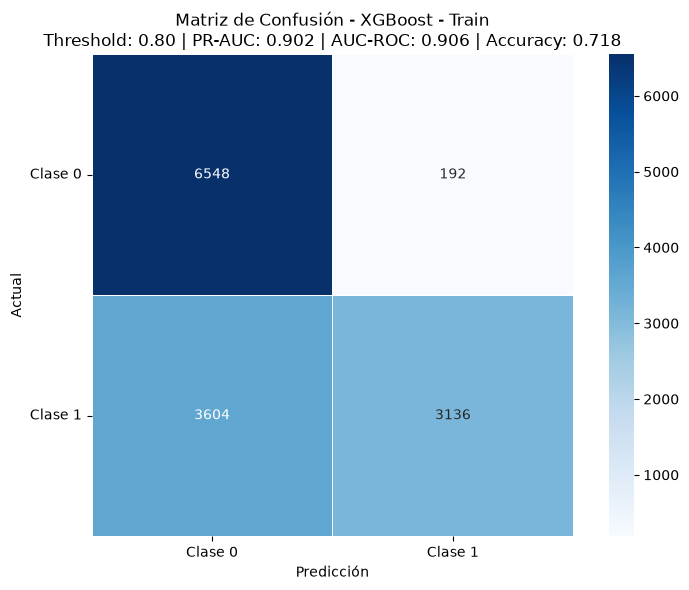


Reporte de Clasificación - XGBoost - Train
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.6450    0.9715    0.7753      6740
     Clase 1     0.9423    0.4653    0.6230      6740

    accuracy                         0.7184     13480
   macro avg     0.7937    0.7184    0.6991     13480
weighted avg     0.7937    0.7184    0.6991     13480

PR-AUC: 0.9021
AUC-ROC: 0.9059
Accuracy: 0.7184


{'model_name': 'XGBoost - Train',
 'threshold': 0.8,
 'pr_auc': 0.902079864460092,
 'auc_roc': 0.9059096342311722,
 'accuracy': 0.7183976261127596,
 'confusion_matrix': array([[6548,  192],
        [3604, 3136]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 1])}

In [138]:
y_train_pred_proba = xgb_best.predict_proba(X_train_resampled)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_train_resampled,
    y_pred_proba=y_train_pred_proba,
    model_name="XGBoost - Train",
    threshold=0.80
)

### Test Evaluation

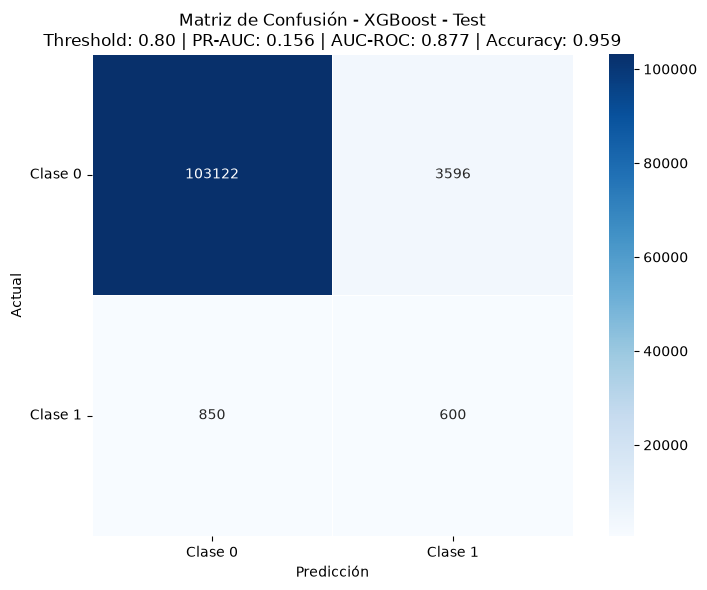


Reporte de Clasificación - XGBoost - Test
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9918    0.9663    0.9789    106718
     Clase 1     0.1430    0.4138    0.2125      1450

    accuracy                         0.9589    108168
   macro avg     0.5674    0.6900    0.5957    108168
weighted avg     0.9804    0.9589    0.9686    108168

PR-AUC: 0.1564
AUC-ROC: 0.8770
Accuracy: 0.9589


{'model_name': 'XGBoost - Test',
 'threshold': 0.8,
 'pr_auc': 0.15640717183986513,
 'auc_roc': 0.8770398459103625,
 'accuracy': 0.9588972709119148,
 'confusion_matrix': array([[103122,   3596],
        [   850,    600]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [139]:
# Obtener las probabilidades predichas para la clase positiva
y_test_pred_proba = xgb_best.predict_proba(X_test)[:, 1]

# Evaluación usando un threshold de 0.85
plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba,
    model_name="XGBoost - Test",
    threshold=0.80
)

### OOT Evaluation

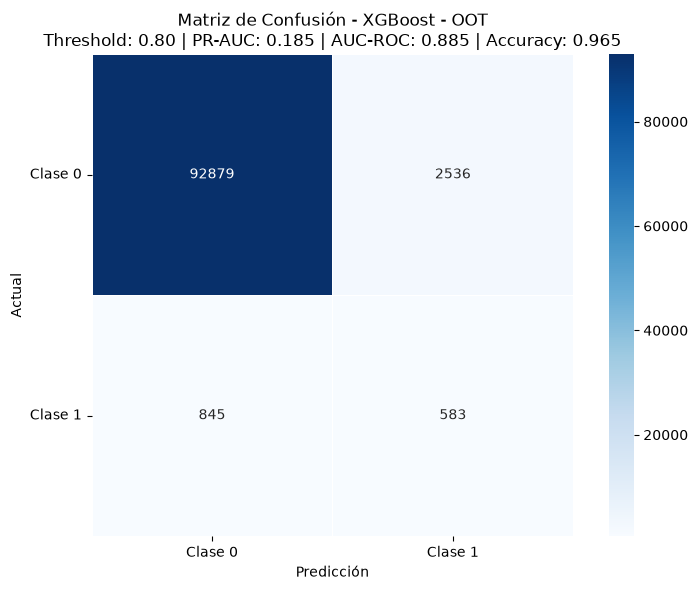


Reporte de Clasificación - XGBoost - OOT
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9910    0.9734    0.9821     95415
     Clase 1     0.1869    0.4083    0.2564      1428

    accuracy                         0.9651     96843
   macro avg     0.5890    0.6908    0.6193     96843
weighted avg     0.9791    0.9651    0.9714     96843

PR-AUC: 0.1846
AUC-ROC: 0.8849
Accuracy: 0.9651


{'model_name': 'XGBoost - OOT',
 'threshold': 0.8,
 'pr_auc': 0.1845856534140725,
 'auc_roc': 0.884899248175925,
 'accuracy': 0.9650878225581612,
 'confusion_matrix': array([[92879,  2536],
        [  845,   583]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [140]:
y_oot_pred_proba = xgb_best.predict_proba(X_oot)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba,
    model_name="XGBoost - OOT",
    threshold=0.80
)

### Feature Importance

In [141]:
# Obtener la importancia de las características del modelo entrenado
feature_importance = xgb_best.feature_importances_

# Crear un DataFrame con la importancia de las características
feature_importance_df = pd.DataFrame({
    'Feature': X_train_resampled.columns,
    'Importance': feature_importance
})

# Ordenar el DataFrame por importancia de mayor a menor
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Configurar pandas para mostrar todas las filas
pd.set_option('display.max_rows', None)

# Mostrar el DataFrame completo
print(feature_importance_df)

# Restablecer la opción para no afectar otras salidas
pd.reset_option('display.max_rows')

                                                Feature  Importance
0                        categoricas__device_os_windows    0.223367
1         sesgadas_constante__prev_address_months_count    0.061623
2                        categoricas__housing_status_BE    0.053470
3                 numericas_mediana__device_trust_score    0.052528
4                  numericas_mediana__credit_risk_score    0.043393
5                    numericas_mediana__has_other_cards    0.042226
6                        categoricas__housing_status_BB    0.037540
7             numericas_mediana__digital_identity_score    0.035947
8                       numericas_mediana__customer_age    0.033815
9                numericas_mediana__contact_consistency    0.032390
10                    categoricas__employment_status_CF    0.027046
11                            numericas_mediana__income    0.026967
12             numericas_mediana__name_email_similarity    0.026192
13         numericas_mediana__device_distinct_em

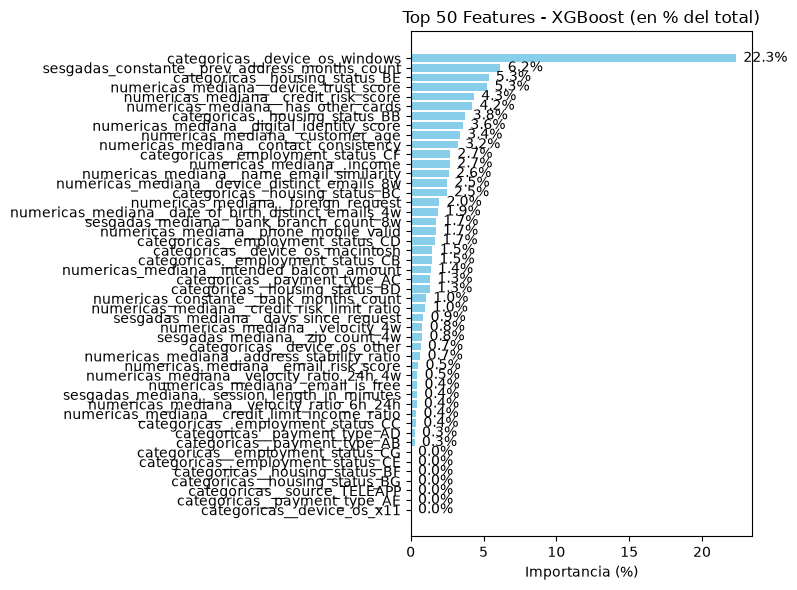

In [142]:
import matplotlib.pyplot as plt

# Top 20 características más importantes de XGBoost
top_n = 50
top_features_xgb = feature_importance_df.head(top_n).copy()

# Calcular el % sobre el total de importancia
total_importance = top_features_xgb['Importance'].sum()
top_features_xgb['Importance_pct'] = top_features_xgb['Importance'] / total_importance * 100

# Gráfico de barras horizontales
plt.figure(figsize=(8, 6))
bars = plt.barh(top_features_xgb['Feature'][::-1], top_features_xgb['Importance_pct'][::-1], color='skyblue')
plt.xlabel('Importancia (%)')
plt.title(f'Top {top_n} Features - XGBoost (en % del total)')

# Añadir etiquetas de % al final de cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5,  # posición X ajustada para que no se encime
             bar.get_y() + bar.get_height() / 2,
             f'{width:.1f}%', va='center')

plt.tight_layout()
plt.show()


### XGBoost - Top 15 Vars

In [ ]:
# ...existing code...

# Nombres originales del pipeline
all_feature_names = prep_lineal.get_feature_names_out()

# Excluir la columna que no quieres considerar
exclude_name = "categoricas__device_os_windows"
keep_mask = np.array([name != exclude_name for name in all_feature_names])

feature_names = all_feature_names[keep_mask]
feature_importances = xgb_best.feature_importances_[keep_mask]

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importances
})

feature_importance = (
    feature_importance
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

# Top 15
top15_importance = feature_importance.head(15)
TOP_15_FEATURES = top15_importance["feature"].tolist()

# Índices originales en el array completo para luego reindexar X_train_resampled
top15_indices = [
    int(np.where(all_feature_names == feature)[0][0])
    for feature in TOP_15_FEATURES
]

TOP_15_FEATURES, top15_indices

(['sesgadas_constante__prev_address_months_count',
  'categoricas__housing_status_BE',
  'numericas_mediana__device_trust_score',
  'numericas_mediana__credit_risk_score',
  'numericas_mediana__has_other_cards',
  'categoricas__housing_status_BB',
  'numericas_mediana__digital_identity_score',
  'numericas_mediana__customer_age',
  'numericas_mediana__contact_consistency',
  'categoricas__employment_status_CF',
  'numericas_mediana__income',
  'numericas_mediana__name_email_similarity',
  'numericas_mediana__device_distinct_emails_8w',
  'categoricas__housing_status_BC',
  'numericas_mediana__foreign_request'],
 [0, 40, 22, 12, 15, 37, 19, 8, 26, 35, 6, 7, 17, 38, 16])

In [150]:
# ============================================================
# Guardar nombres de las 15 variables más importantes
# ============================================================

TOP_15_FEATURES = top15_importance["feature"].tolist()

TOP_15_FEATURES


# ============================================================
# Índices correspondientes a las variables Top 15
# ============================================================

top15_indices = [
    list(feature_names).index(feature)
    for feature in TOP_15_FEATURES
]

top15_indices

[0, 40, 22, 12, 15, 37, 19, 8, 26, 35, 6, 7, 17, 38, 16]

In [151]:
# ============================================================
# Seleccionar solamente las 15 variables más importantes
# ============================================================

X_train_resampled_top15 = X_train_resampled.iloc[:, top15_indices].copy()

X_val_top15 = X_val[:, top15_indices]

X_test_top15 = X_test[:, top15_indices]

X_oot_top15 = X_oot[:, top15_indices]


print("Train Top 15:", X_train_resampled_top15.shape)
print("Validation Top 15:", X_val_top15.shape)
print("Test Top 15:", X_test_top15.shape)
print("OOT Top 15:", X_oot_top15.shape)

Train Top 15: (13480, 15)
Validation Top 15: (119323, 15)
Test Top 15: (108168, 15)
OOT Top 15: (96843, 15)


In [152]:
from bayes_opt import BayesianOptimization
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

# ============================================================
# Función objetivo - Modelo Top 15
# ============================================================

def xgb_evaluate_top15(
    max_depth,
    gamma,
    colsample_bytree,
    learning_rate,
    n_estimators,
    subsample,
    min_child_weight,
    reg_alpha,
    reg_lambda
):
    """
    Entrena XGBoost utilizando solamente las 15 variables
    más importantes y maximiza PR-AUC sobre validation.
    """

    params = {
        "objective": "binary:logistic",
        "eval_metric": "aucpr",

        "max_depth": int(round(max_depth)),
        "gamma": gamma,
        "colsample_bytree": colsample_bytree,
        "learning_rate": learning_rate,
        "n_estimators": int(round(n_estimators)),
        "subsample": subsample,
        "min_child_weight": min_child_weight,

        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,

        # Train ya fue balanceado mediante undersampling,
        # por lo que no utilizamos scale_pos_weight.
        "random_state": 150718,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    # Entrenamiento con las 15 variables seleccionadas
    model.fit(
        X_train_resampled_top15,
        y_train_resampled
    )

    # Validation conserva la distribución real de fraude
    y_val_pred_proba = model.predict_proba(
        X_val_top15
    )[:, 1]

    # Bayesian Optimization maximizará PR-AUC
    return average_precision_score(
        y_val,
        y_val_pred_proba
    )

#### Espacio de Busqueda

In [153]:
params_pbounds_top15 = {
    "max_depth": (3, 6),
    "gamma": (0, 10),
    "colsample_bytree": (0.5, 0.9),
    "learning_rate": (0.01, 0.1),
    "n_estimators": (50, 100),
    "subsample": (0.6, 0.95),
    "min_child_weight": (5, 40),
    "reg_alpha": (0, 20),
    "reg_lambda": (1, 20)
}

#### Optimizacion Bayesiana

In [154]:
# ============================================================
# Optimización Bayesiana - Modelo Top 15
# ============================================================

xgb_bo_top15 = BayesianOptimization(
    f=xgb_evaluate_top15,
    pbounds=params_pbounds_top15,
    random_state=42,
    verbose=2
)

xgb_bo_top15.maximize(
    init_points=10,
    n_iter=10
)

|   iter    |  target   | colsam... |   gamma   | learni... | max_depth | min_ch... | n_esti... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.108     | 0.6498    | 9.507     | 0.07588   | 4.796     | 10.46     | 57.8      | 1.162     | 17.46     | 0.8104    |
| 2         | 0.1164    | 0.7832    | 0.2058    | 0.09729   | 5.497     | 12.43     | 59.09     | 3.668     | 6.781     | 0.7837    |
| 3         | 0.1037    | 0.6728    | 2.912     | 0.06507   | 3.418     | 15.23     | 68.32     | 9.121     | 15.92     | 0.6699    |
| 4         | 0.08656   | 0.7057    | 5.924     | 0.01418   | 4.823     | 10.97     | 53.25     | 18.98     | 19.35     | 0.8829    |
| 5         | 0.1132    | 0.6218    | 0.9767    | 0.07158   | 4.32      | 9.271     | 74.76     | 0.6878    | 18.28     | 0.6906    |
| 6         | 0.1069    | 0.765     | 3.117     | 0.05681   | 

#### Mejores Parámetros

In [155]:
best_params_top15 = xgb_bo_top15.max["params"].copy()

# Parámetros que necesariamente deben ser enteros
best_params_top15["max_depth"] = int(
    round(best_params_top15["max_depth"])
)

best_params_top15["n_estimators"] = int(
    round(best_params_top15["n_estimators"])
)

print("\nMejores parámetros - XGBoost Top 15:")

for parametro, valor in best_params_top15.items():
    print(f"{parametro}: {valor}")


Mejores parámetros - XGBoost Top 15:
colsample_bytree: 0.7832290311184182
gamma: 0.20584494295802447
learning_rate: 0.0972918866945795
max_depth: 5
min_child_weight: 12.431868873739665
n_estimators: 59
reg_alpha: 3.6680901970686763
reg_lambda: 6.780602616231217
subsample: 0.7836647510712832


#### Training

In [156]:
best_params_top15 = xgb_bo_top15.max["params"].copy()

# Parámetros que necesariamente deben ser enteros
best_params_top15["max_depth"] = int(
    round(best_params_top15["max_depth"])
)

best_params_top15["n_estimators"] = int(
    round(best_params_top15["n_estimators"])
)

print("\nMejores parámetros - XGBoost Top 15:")

for parametro, valor in best_params_top15.items():
    print(f"{parametro}: {valor}")

# ============================================================
# 2. Crear modelo final con los mejores parámetros
# ============================================================

xgb_best_top15 = XGBClassifier(
    **best_params_top15,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=150718,
    n_jobs=-1
)


# ============================================================
# 3. Entrenar modelo final Top 15
# ============================================================

xgb_best_top15.fit(
    X_train_resampled_top15,
    y_train_resampled
)

print("\nModelo XGBoost Top 15 entrenado correctamente.")


Mejores parámetros - XGBoost Top 15:
colsample_bytree: 0.7832290311184182
gamma: 0.20584494295802447
learning_rate: 0.0972918866945795
max_depth: 5
min_child_weight: 12.431868873739665
n_estimators: 59
reg_alpha: 3.6680901970686763
reg_lambda: 6.780602616231217
subsample: 0.7836647510712832

Modelo XGBoost Top 15 entrenado correctamente.


#### Evaluacion

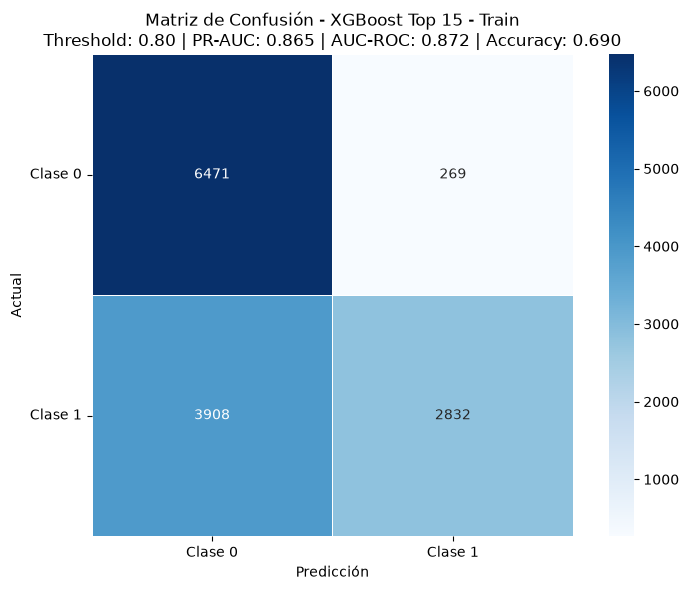


Reporte de Clasificación - XGBoost Top 15 - Train
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.6235    0.9601    0.7560      6740
     Clase 1     0.9133    0.4202    0.5756      6740

    accuracy                         0.6901     13480
   macro avg     0.7684    0.6901    0.6658     13480
weighted avg     0.7684    0.6901    0.6658     13480

PR-AUC: 0.8650
AUC-ROC: 0.8716
Accuracy: 0.6901


{'model_name': 'XGBoost Top 15 - Train',
 'threshold': 0.8,
 'pr_auc': 0.8650006172672148,
 'auc_roc': 0.871583695814879,
 'accuracy': 0.69013353115727,
 'confusion_matrix': array([[6471,  269],
        [3908, 2832]], dtype=int64),
 'y_pred': array([0, 1, 0, ..., 0, 0, 1])}

In [157]:
y_train_pred_proba_top15 = (
    xgb_best_top15
    .predict_proba(X_train_resampled_top15)[:, 1]
)

plot_confusion_matrix_heatmap(
    y_true=y_train_resampled,
    y_pred_proba=y_train_pred_proba_top15,
    model_name="XGBoost Top 15 - Train",
    threshold=0.80
)

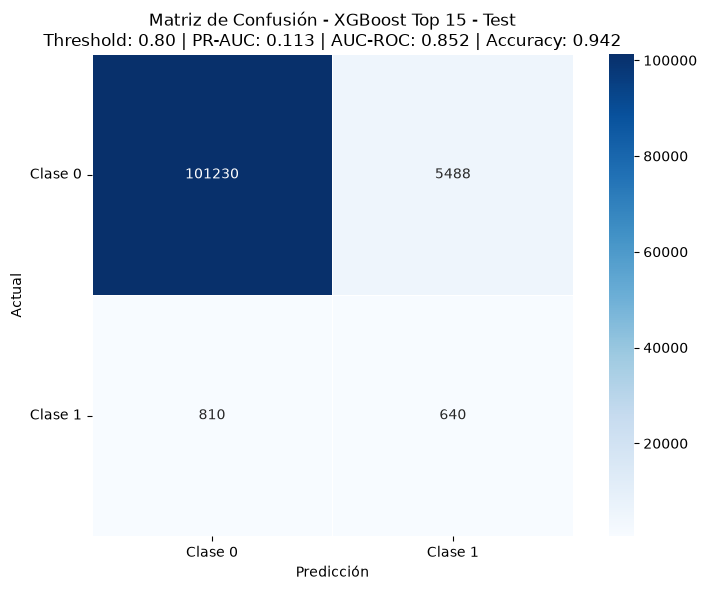


Reporte de Clasificación - XGBoost Top 15 - Test
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9921    0.9486    0.9698    106718
     Clase 1     0.1044    0.4414    0.1689      1450

    accuracy                         0.9418    108168
   macro avg     0.5483    0.6950    0.5694    108168
weighted avg     0.9802    0.9418    0.9591    108168

PR-AUC: 0.1130
AUC-ROC: 0.8524
Accuracy: 0.9418


{'model_name': 'XGBoost Top 15 - Test',
 'threshold': 0.8,
 'pr_auc': 0.11303034196761594,
 'auc_roc': 0.8524398559917178,
 'accuracy': 0.941775756231048,
 'confusion_matrix': array([[101230,   5488],
        [   810,    640]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [158]:
y_test_pred_proba_top15 = (
    xgb_best_top15
    .predict_proba(X_test_top15)[:, 1]
)

plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba_top15,
    model_name="XGBoost Top 15 - Test",
    threshold=0.80
)

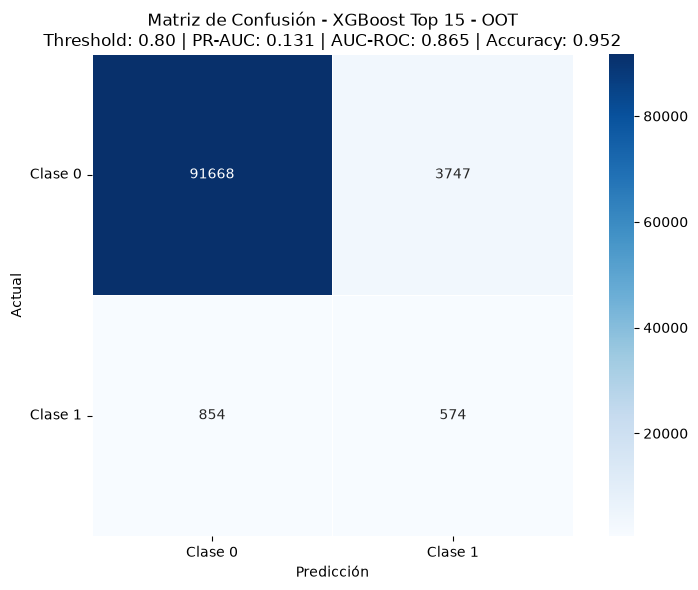


Reporte de Clasificación - XGBoost Top 15 - OOT
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9908    0.9607    0.9755     95415
     Clase 1     0.1328    0.4020    0.1997      1428

    accuracy                         0.9525     96843
   macro avg     0.5618    0.6813    0.5876     96843
weighted avg     0.9781    0.9525    0.9641     96843

PR-AUC: 0.1311
AUC-ROC: 0.8646
Accuracy: 0.9525


{'model_name': 'XGBoost Top 15 - OOT',
 'threshold': 0.8,
 'pr_auc': 0.1311093841569311,
 'auc_roc': 0.8646473843952506,
 'accuracy': 0.9524901128630877,
 'confusion_matrix': array([[91668,  3747],
        [  854,   574]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [159]:
y_oot_pred_proba_top15 = (
    xgb_best_top15
    .predict_proba(X_oot_top15)[:, 1]
)

plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba_top15,
    model_name="XGBoost Top 15 - OOT",
    threshold=0.80
)

In [160]:
# Obtener la importancia de las características del modelo entrenado
feature_importance = xgb_best_top15.feature_importances_

# Crear un DataFrame con la importancia de las características
feature_importance_df = pd.DataFrame({
    'Feature': X_train_resampled_top15.columns,
    'Importance': feature_importance
})

# Ordenar el DataFrame por importancia de mayor a menor
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Configurar pandas para mostrar todas las filas
pd.set_option('display.max_rows', None)

# Mostrar el DataFrame completo
print(feature_importance_df)

# Restablecer la opción para no afectar otras salidas
pd.reset_option('display.max_rows')

                                          Feature  Importance
0   sesgadas_constante__prev_address_months_count    0.121382
1                  categoricas__housing_status_BE    0.107569
2           numericas_mediana__device_trust_score    0.099479
3          numericas_mediana__contact_consistency    0.087762
4              numericas_mediana__has_other_cards    0.083295
5                 numericas_mediana__customer_age    0.070308
6            numericas_mediana__credit_risk_score    0.069559
7                  categoricas__housing_status_BB    0.062384
8                  categoricas__housing_status_BC    0.062320
9       numericas_mediana__digital_identity_score    0.057295
10              categoricas__employment_status_CF    0.044444
11                      numericas_mediana__income    0.042831
12   numericas_mediana__device_distinct_emails_8w    0.038542
13       numericas_mediana__name_email_similarity    0.027366
14             numericas_mediana__foreign_request    0.025464


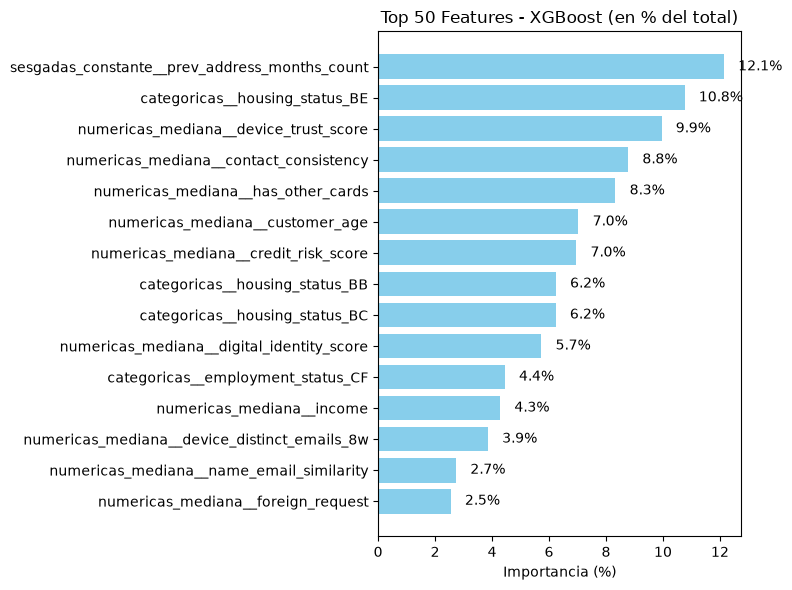

In [161]:
# Top 20 características más importantes de XGBoost
top_n = 50
top_features_xgb = feature_importance_df.head(top_n).copy()

# Calcular el % sobre el total de importancia
total_importance = top_features_xgb['Importance'].sum()
top_features_xgb['Importance_pct'] = top_features_xgb['Importance'] / total_importance * 100

# Gráfico de barras horizontales
plt.figure(figsize=(8, 6))
bars = plt.barh(top_features_xgb['Feature'][::-1], top_features_xgb['Importance_pct'][::-1], color='skyblue')
plt.xlabel('Importancia (%)')
plt.title(f'Top {top_n} Features - XGBoost (en % del total)')

# Añadir etiquetas de % al final de cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5,  # posición X ajustada para que no se encime
             bar.get_y() + bar.get_height() / 2,
             f'{width:.1f}%', va='center')

plt.tight_layout()
plt.show()


#### Fairness

In [ ]:
# ============================================================
# FAIRNESS: auditoría de paridad + proxy analysis
# ============================================================

import pandas as pd
import numpy as np

# ============================================================
# 1. Definir el score y la predicción
# ============================================================

# Elige el score del modelo que quieras evaluar.
# Ejemplos:
# score_col = y_test_pred_proba_top15
# score_col = y_test_pred_proba_lgbm

score_col = y_test_pred_proba_top15  # <- cambiar si usas otro modelo

fairness_df = test_data.copy()
fairness_df["score"] = score_col
fairness_df["target"] = y_test.values
fairness_df["pred"] = (fairness_df["score"] >= 0.80).astype(int)

print("Base fairness_df:")
fairness_df[["score", "pred", "target"]].head()


# ============================================================
# 2. Variables sensibles / proxies candidatas
# ============================================================

# Importante: no veo una columna real de gender/race.
# Estas son las columnas que más probablemente actúan como proxy.

proxy_candidates = [
    "customer_age",
    "income",
    "housing_status",
    "employment_status",
    "device_os",
    "source",
    "zip_code",
    "bank_branch_count_8w",
    "has_other_cards",
    "foreign_request"
]

print("\nVariables proxy candidatas presentes:")
for c in proxy_candidates:
    if c in fairness_df.columns:
        print(" -", c)


# ============================================================
# 3. Funciones auxiliares
# ============================================================

def group_summary(df, group_col):
    """
    Calcula:
    - selection_rate = P(pred=1)
    - base_rate = P(target=1)
    - TPR = P(pred=1 | target=1)
    - FPR = P(pred=1 | target=0)
    """
    g = df.groupby(group_col, dropna=False)

    selection_rate = g["pred"].mean().rename("selection_rate")
    base_rate = g["target"].mean().rename("base_rate")

    tpr = (
        df[df["target"] == 1]
        .groupby(group_col, dropna=False)["pred"]
        .mean()
        .rename("TPR")
    )

    fpr = (
        df[df["target"] == 0]
        .groupby(group_col, dropna=False)["pred"]
        .mean()
        .rename("FPR")
    )

    res = pd.concat(
        [selection_rate, base_rate, tpr, fpr],
        axis=1
    ).reset_index()

    res.columns = ["group", "selection_rate", "base_rate", "TPR", "FPR"]

    return res


def make_group_column(s, col_name, mode="auto"):
    s = s.copy()
    s = s.fillna("Missing")

    if mode == "auto":
        if pd.api.types.is_numeric_dtype(s):
            # Binning para edad e income
            if col_name in ["customer_age", "income"]:
                if col_name == "customer_age":
                    bins = [0, 25, 35, 45, 55, 65, 120]
                    labels = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
                else:
                    bins = [0, 1000, 2000, 5000, 10000, 20000, 1e9]
                    labels = ["<1k", "1k-2k", "2k-5k", "5k-10k", "10k-20k", "20k+"]
                return pd.cut(s, bins=bins, labels=labels, right=False)
            return pd.qcut(s, q=4, duplicates="drop")
        return s.astype(str)

    return s.astype(str)


# ============================================================
# 4. Evaluación de fairness por cada proxy
# ============================================================

for col in proxy_candidates:
    if col not in fairness_df.columns:
        continue

    print(f"\n\n================================================")
    print(f"FAIRNESS: {col}")
    print("================================================")

    grouped = fairness_df.copy()
    grouped["group"] = make_group_column(grouped[col], col, mode="auto")

    summary = group_summary(grouped, "group")
    print(summary.sort_values("group").to_string(index=False))

    # Diferencias absolutas por grupo
    if not summary.empty:
        selection_gap = summary["selection_rate"].max() - summary["selection_rate"].min()
        tpr_gap = summary["TPR"].max() - summary["TPR"].min()
        fpr_gap = summary["FPR"].max() - summary["FPR"].min()

        print(f"\nSelection rate gap: {selection_gap:.4f}")
        print(f"TPR gap: {tpr_gap:.4f}")
        print(f"FPR gap: {fpr_gap:.4f}")

        # Disparate impact ratio
        sr_min = summary["selection_rate"].min()
        sr_max = summary["selection_rate"].max()
        disparate_impact = sr_min / sr_max if sr_max > 0 else np.nan
        print(f"Disparate Impact ratio: {disparate_impact:.4f}")


# ============================================================
# 5. Proxy audit: correlación entre score y proxy
# ============================================================

print("\n\n================================================")
print("PROXY AUDIT: correlación score vs proxy")
print("================================================")

for col in ["customer_age", "income", "bank_branch_count_8w", "zip_code", "has_other_cards"]:
    if col in fairness_df.columns and pd.api.types.is_numeric_dtype(fairness_df[col]):
        corr = fairness_df[col].corr(fairness_df["score"], method="spearman")
        print(f"{col}: Spearman corr(score) = {corr:.4f}")


# ============================================================
# 6. Proxy audit: diferencia en score por grupo
# ============================================================

for col in ["housing_status", "employment_status", "device_os", "source"]:
    if col in fairness_df.columns:
        grouped = fairness_df.copy()
        grouped["group"] = grouped[col].fillna("Missing").astype(str)

        score_by_group = (
            grouped
            .groupby("group", dropna=False)["score"]
            .mean()
            .sort_values(ascending=False)
        )

        fraud_by_group = (
            grouped
            .groupby("group", dropna=False)["target"]
            .mean()
            .sort_values(ascending=False)
        )

        print(f"\n=== {col} ===")
        print("Mean score by group:")
        print(score_by_group)
        print("\nFraud rate by group:")
        print(fraud_by_group)


# ============================================================
# 7. Si quieres una métrica más formal: Demographic Parity
# ============================================================

# Reutiliza una variable proxy o protegida real si la tienes.
# Por ejemplo "customer_age" o "housing_status".
protected_col = "customer_age"  # <- ajustar según corresponda

if protected_col in fairness_df.columns:
    fair_subset = fairness_df.copy()
    fair_subset["protected_group"] = make_group_column(
        fair_subset[protected_col],
        protected_col,
        mode="auto"
    )

    summary = group_summary(fair_subset, "protected_group")
    print("\n\nDemographic Parity por protected_group:")
    print(summary.sort_values("group").to_string(index=False))
else:
    print(f"\nLa columna protegida '{protected_col}' no existe; no se calcula parity por esa variable.")


Base fairness_df:

Variables proxy candidatas presentes:
 - customer_age
 - income
 - housing_status
 - employment_status
 - device_os
 - source
 - bank_branch_count_8w
 - has_other_cards
 - foreign_request


FAIRNESS: customer_age
group  selection_rate  base_rate      TPR      FPR
  <25        0.010115   0.005894 0.203704 0.008967
25-34        0.032204   0.009981 0.288026 0.029625
35-44        0.063957   0.014259 0.431373 0.058642
45-54        0.131465   0.023447 0.558824 0.121204
55-64        0.179914   0.036841 0.684932 0.160597
  65+        0.177796   0.042571 0.647059 0.156931

Selection rate gap: 0.1698
TPR gap: 0.4812
FPR gap: 0.1516
Disparate Impact ratio: 0.0562


FAIRNESS: income
  group  selection_rate  base_rate      TPR      FPR
    <1k        0.056653   0.013405 0.441379 0.051425
  1k-2k             NaN        NaN      NaN      NaN
  2k-5k             NaN        NaN      NaN      NaN
 5k-10k             NaN        NaN      NaN      NaN
10k-20k             NaN        NaN  

C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = df.groupby(group_col, dropna=False)
C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(group_col, dropna=False)["pred"]
C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  

group  selection_rate  base_rate      TPR      FPR
   BA        0.245004   0.042813 0.642616 0.227220
   BB        0.005488   0.006694 0.099099 0.004857
   BC        0.012972   0.006990 0.148472 0.012019
   BD        0.109740   0.007513 0.428571 0.107326
   BE        0.000739   0.004773 0.023810 0.000628
   BF        0.113636   0.000000      NaN 0.113636
   BG        0.125000   0.000000      NaN 0.125000

Selection rate gap: 0.2443
TPR gap: 0.6188
FPR gap: 0.2266
Disparate Impact ratio: 0.0030


FAIRNESS: employment_status
group  selection_rate  base_rate      TPR      FPR
   CA        0.058967   0.014530 0.440066 0.053348
   CB        0.058722   0.008735 0.415842 0.055575
   CC        0.099623   0.027791 0.508475 0.087936
   CD        0.019960   0.000499 0.000000 0.019970
   CE        0.012620   0.002611 0.333333 0.011780
   CF        0.002627   0.001433 0.000000 0.002631
   CG        0.069767   0.000000      NaN 0.069767

Selection rate gap: 0.0970
TPR gap: 0.5085
FPR gap: 0.0853
Dis

C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = df.groupby(group_col, dropna=False)
C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(group_col, dropna=False)["pred"]
C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  

         group  selection_rate  base_rate      TPR      FPR
 (-0.001, 1.0]        0.068577   0.020955 0.489458 0.059569
    (1.0, 9.0]        0.051324   0.010159 0.393574 0.047811
   (9.0, 21.0]        0.055784   0.012747 0.391850 0.051445
(21.0, 2385.0]        0.048284   0.008091 0.422018 0.045235

Selection rate gap: 0.0203
TPR gap: 0.0976
FPR gap: 0.0143
Disparate Impact ratio: 0.7041


FAIRNESS: has_other_cards
        group  selection_rate  base_rate      TPR      FPR
(-0.001, 1.0]        0.056653   0.013405 0.441379 0.051425

Selection rate gap: 0.0000
TPR gap: 0.0000
FPR gap: 0.0000
Disparate Impact ratio: 1.0000


FAIRNESS: foreign_request
        group  selection_rate  base_rate      TPR      FPR
(-0.001, 1.0]        0.056653   0.013405 0.441379 0.051425

Selection rate gap: 0.0000
TPR gap: 0.0000
FPR gap: 0.0000
Disparate Impact ratio: 1.0000


PROXY AUDIT: correlación score vs proxy
customer_age: Spearman corr(score) = 0.3370
income: Spearman corr(score) = 0.2918
bank_branch

C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:68: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = df.groupby(group_col, dropna=False)
C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(group_col, dropna=False)["pred"]
C:\Users\Renzo\AppData\Local\Temp\ipykernel_40248\2818279559.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  

In [194]:
# ============================================================
# FAIRNESS AUDIT LIMPIO
# ============================================================

import pandas as pd
import numpy as np

# score del modelo que quieras evaluar
score_col = y_test_pred_proba_top15

fairness_df = test_data.copy()
fairness_df["score"] = score_col
fairness_df["target"] = y_test.to_numpy()
fairness_df["pred"] = (fairness_df["score"] >= 0.80).astype(int)

proxy_candidates = [
    "customer_age",
    "income",
    "housing_status",
    "employment_status",
    "device_os",
    "source",
    "zip_code",
    "bank_branch_count_8w",
    "has_other_cards",
    "foreign_request"
]

def make_group_column(s, col_name):
    s = s.copy().fillna("Missing")
    if pd.api.types.is_numeric_dtype(s):
        if col_name in ["customer_age", "income"]:
            if col_name == "customer_age":
                bins = [0, 25, 35, 45, 55, 65, 120]
                labels = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
            else:
                bins = [0, 1000, 2000, 5000, 10000, 20000, 1e9]
                labels = ["<1k", "1k-2k", "2k-5k", "5k-10k", "10k-20k", "20k+"]
            return pd.cut(s, bins=bins, labels=labels, right=False)
        return pd.qcut(s, q=4, duplicates="drop")
    return s.astype(str)

def group_summary(df, group_col):
    g = df.groupby(group_col, dropna=False, observed=False)
    selection_rate = g["pred"].mean().rename("selection_rate")
    base_rate = g["target"].mean().rename("base_rate")
    tpr = (
        df[df["target"] == 1]
        .groupby(group_col, dropna=False, observed=False)["pred"]
        .mean()
        .rename("TPR")
    )
    fpr = (
        df[df["target"] == 0]
        .groupby(group_col, dropna=False, observed=False)["pred"]
        .mean()
        .rename("FPR")
    )
    out = pd.concat([selection_rate, base_rate, tpr, fpr], axis=1).reset_index()
    out.columns = ["group", "selection_rate", "base_rate", "TPR", "FPR"]
    return out

# 1) Fairness por proxy
for col in proxy_candidates:
    if col not in fairness_df.columns:
        continue

    grouped = fairness_df.copy()
    grouped["group"] = make_group_column(grouped[col], col)

    summary = group_summary(grouped, "group")
    print(f"\n=== {col} ===")
    print(summary.sort_values("group").to_string(index=False))

    if not summary.empty:
        selection_gap = summary["selection_rate"].max() - summary["selection_rate"].min()
        tpr_gap = summary["TPR"].max() - summary["TPR"].min()
        fpr_gap = summary["FPR"].max() - summary["FPR"].min()
        disparate_impact = (summary["selection_rate"].min() / summary["selection_rate"].max()) if summary["selection_rate"].max() > 0 else np.nan

        print(f"Selection rate gap: {selection_gap:.4f}")
        print(f"TPR gap: {tpr_gap:.4f}")
        print(f"FPR gap: {fpr_gap:.4f}")
        print(f"Disparate Impact ratio: {disparate_impact:.4f}")

# 2) Correlación score vs proxy
print("\n=== Correlaciones score vs proxy ===")
for col in ["customer_age", "income", "bank_branch_count_8w", "has_other_cards"]:
    if col in fairness_df.columns and pd.api.types.is_numeric_dtype(fairness_df[col]):
        corr = fairness_df[col].corr(fairness_df["score"], method="spearman")
        print(f"{col}: {corr:.4f}")

# 3) Comparación de score medio por grupo
for col in ["housing_status", "employment_status", "device_os", "source"]:
    if col in fairness_df.columns:
        grouped = fairness_df.copy()
        grouped["group"] = grouped[col].fillna("Missing").astype(str)
        print(f"\n=== {col} ===")
        print(grouped.groupby("group", dropna=False, observed=False)["score"].mean().sort_values(ascending=False))
        print(grouped.groupby("group", dropna=False, observed=False)["target"].mean().sort_values(ascending=False))

# 4) Demo parity con edad como proxy
protected_col = "customer_age"
if protected_col in fairness_df.columns:
    fair_subset = fairness_df.copy()
    fair_subset["protected_group"] = make_group_column(fair_subset[protected_col], protected_col)
    summary = group_summary(fair_subset, "protected_group")
    print("\n=== Demographic Parity por edad ===")
    print(summary.sort_values("group").to_string(index=False))


=== customer_age ===
group  selection_rate  base_rate      TPR      FPR
  <25        0.010115   0.005894 0.203704 0.008967
25-34        0.032204   0.009981 0.288026 0.029625
35-44        0.063957   0.014259 0.431373 0.058642
45-54        0.131465   0.023447 0.558824 0.121204
55-64        0.179914   0.036841 0.684932 0.160597
  65+        0.177796   0.042571 0.647059 0.156931
Selection rate gap: 0.1698
TPR gap: 0.4812
FPR gap: 0.1516
Disparate Impact ratio: 0.0562

=== income ===
  group  selection_rate  base_rate      TPR      FPR
    <1k        0.056653   0.013405 0.441379 0.051425
  1k-2k             NaN        NaN      NaN      NaN
  2k-5k             NaN        NaN      NaN      NaN
 5k-10k             NaN        NaN      NaN      NaN
10k-20k             NaN        NaN      NaN      NaN
   20k+             NaN        NaN      NaN      NaN
Selection rate gap: 0.0000
TPR gap: 0.0000
FPR gap: 0.0000
Disparate Impact ratio: 1.0000

=== housing_status ===
group  selection_rate  base_ra

In [196]:
# ...existing code...

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# ============================================================
# 1) Datos del fairness report
# ============================================================

fairness_data = {
    "customer_age": {
        "table": pd.DataFrame(
            [
                ["<25", 0.010115, 0.005894, 0.203704, 0.008967],
                ["25-34", 0.032204, 0.009981, 0.288026, 0.029625],
                ["35-44", 0.063957, 0.014259, 0.431373, 0.058642],
                ["45-54", 0.131465, 0.023447, 0.558824, 0.121204],
                ["55-64", 0.179914, 0.036841, 0.684932, 0.160597],
                ["65+", 0.177796, 0.042571, 0.647059, 0.156931],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.1698,
            "TPR gap": 0.4812,
            "FPR gap": 0.1516,
            "Disparate Impact ratio": 0.0562,
        },
        "notes": [
            "El modelo dispara mucho más a personas mayores.",
            "La tasa de selección en 55-64 y 65+ es ~18% frente a ~1% en <25.",
            "Hay disparidad fuerte en TPR y FPR entre grupos de edad."
        ],
    },
    "income": {
        "table": pd.DataFrame(
            [
                ["<1k", 0.056653, 0.013405, 0.441379, 0.051425],
                ["1k-2k", np.nan, np.nan, np.nan, np.nan],
                ["2k-5k", np.nan, np.nan, np.nan, np.nan],
                ["5k-10k", np.nan, np.nan, np.nan, np.nan],
                ["10k-20k", np.nan, np.nan, np.nan, np.nan],
                ["20k+", np.nan, np.nan, np.nan, np.nan],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0000,
            "TPR gap": 0.0000,
            "FPR gap": 0.0000,
            "Disparate Impact ratio": 1.0000,
        },
        "notes": [
            "La distribución del grupo para income no está completa en este subconjunto.",
            "A nivel observado, no hay diferencia directa en selección entre grupos.",
            "Se recomienda validar este proxy en más volumen de datos."
        ],
    },
    "housing_status": {
        "table": pd.DataFrame(
            [
                ["BA", 0.245004, 0.042813, 0.642616, 0.227220],
                ["BB", 0.005488, 0.006694, 0.099099, 0.004857],
                ["BC", 0.012972, 0.006990, 0.148472, 0.012019],
                ["BD", 0.109740, 0.007513, 0.428571, 0.107326],
                ["BE", 0.000739, 0.004773, 0.023810, 0.000628],
                ["BF", 0.113636, 0.000000, np.nan, 0.113636],
                ["BG", 0.125000, 0.000000, np.nan, 0.125000],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.2443,
            "TPR gap": 0.6188,
            "FPR gap": 0.2266,
            "Disparate Impact ratio": 0.0030,
        },
        "notes": [
            "Este es un proxy muy fuerte de estatus socioeconómico.",
            "BA tiene ~24% de selección vs ~0.07% en BE.",
            "Hay diferencias muy altas de TPR y FPR por grupo."
        ],
    },
    "employment_status": {
        "table": pd.DataFrame(
            [
                ["CA", 0.058967, 0.014530, 0.440066, 0.053348],
                ["CB", 0.058722, 0.008735, 0.415842, 0.055575],
                ["CC", 0.099623, 0.027791, 0.508475, 0.087936],
                ["CD", 0.019960, 0.000499, 0.000000, 0.019970],
                ["CE", 0.012620, 0.002611, 0.333333, 0.011780],
                ["CF", 0.002627, 0.001433, 0.000000, 0.002631],
                ["CG", 0.069767, 0.000000, np.nan, 0.069767],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0970,
            "TPR gap": 0.5085,
            "FPR gap": 0.0853,
            "Disparate Impact ratio": 0.0264,
        },
        "notes": [
            "La variable de empleo muestra diferencias notables de riesgo.",
            "CC tiene mayor tasa de selección que CF/CE.",
            "El proxy de estatus laboral está afectando la decisión."
        ],
    },
    "device_os": {
        "table": pd.DataFrame(
            [
                ["linux", 0.045890, 0.007479, 0.408511, 0.043158],
                ["macintosh", 0.073772, 0.018868, 0.423423, 0.067048],
                ["other", 0.040591, 0.007113, 0.362776, 0.038282],
                ["windows", 0.093675, 0.030583, 0.484576, 0.081343],
                ["x11", 0.070093, 0.010514, 0.555556, 0.064935],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0531,
            "TPR gap": 0.1928,
            "FPR gap": 0.0431,
            "Disparate Impact ratio": 0.4333,
        },
        "notes": [
            "Windows recibe más inspección que linux o other.",
            "Hay diferencia sistemática por sistema operativo.",
            "Device OS puede funcionar como proxy de perfil del solicitante."
        ],
    },
    "source": {
        "table": pd.DataFrame(
            [
                ["INTERNET", 0.056595, 0.013354, 0.442737, 0.051369],
                ["TELEAPP", 0.063237, 0.019293, 0.333333, 0.057923],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0066,
            "TPR gap": 0.1094,
            "FPR gap": 0.0066,
            "Disparate Impact ratio": 0.8950,
        },
        "notes": [
            "Hay una diferencia pequeña pero consistente por canal de solicitud.",
            "No es tan fuerte como edad o housing_status, pero sí se observa."
        ],
    },
    "bank_branch_count_8w": {
        "table": pd.DataFrame(
            [
                ["(-0.001, 1.0]", 0.068577, 0.020955, 0.489458, 0.059569],
                ["(1.0, 9.0]", 0.051324, 0.010159, 0.393574, 0.047811],
                ["(9.0, 21.0]", 0.055784, 0.012747, 0.391850, 0.051445],
                ["(21.0, 2385.0]", 0.048284, 0.008091, 0.422018, 0.045235],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0203,
            "TPR gap": 0.0976,
            "FPR gap": 0.0143,
            "Disparate Impact ratio": 0.7041,
        },
        "notes": [
            "La variable tiene diferencia moderada de selección entre grupos.",
            "No es extremo, pero puede actuar como proxy indirecto."
        ],
    },
    "has_other_cards": {
        "table": pd.DataFrame(
            [
                ["(-0.001, 1.0]", 0.056653, 0.013405, 0.441379, 0.051425],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0000,
            "TPR gap": 0.0000,
            "FPR gap": 0.0000,
            "Disparate Impact ratio": 1.0000,
        },
        "notes": [
            "No hay variación aparente en este proxy.",
            "No parece ser una fuente material de disparidad."
        ],
    },
    "foreign_request": {
        "table": pd.DataFrame(
            [
                ["(-0.001, 1.0]", 0.056653, 0.013405, 0.441379, 0.051425],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.0000,
            "TPR gap": 0.0000,
            "FPR gap": 0.0000,
            "Disparate Impact ratio": 1.0000,
        },
        "notes": [
            "No hay evidencia de disparidad por esta variable.",
            "No parece ser un proxy relevante en este dataset."
        ],
    },
    "correlations": {
        "table": pd.DataFrame(
            [
                ["customer_age", 0.3370],
                ["income", 0.2918],
                ["bank_branch_count_8w", -0.0251],
                ["has_other_cards", -0.2376],
            ],
            columns=["proxy", "spearman_corr"]
        ),
        "summary": {
            "Mayor correlación": "customer_age",
            "valor": 0.3370,
        },
        "notes": [
            "customer_age e income son los proxies con mayor asociación con el score.",
            "customer_age es el más relevante en términos de impacto marginal.",
            "Los otros dos tienen relación moderada o negativa."
        ],
    },
    "mean_score_by_group": {
        "table": pd.DataFrame(
            [
                ["BA", 0.594183],
                ["BD", 0.474359],
                ["BF", 0.468221],
                ["BG", 0.427075],
                ["BB", 0.297856],
                ["BC", 0.284004],
                ["BE", 0.247375],
            ],
            columns=["group", "mean_score"]
        ),
        "summary": {
            "max": 0.594183,
            "min": 0.247375,
            "gap": 0.346808,
        },
        "notes": [
            "La diferencia de score medio por grupo es muy grande.",
            "BA recibe score mucho mayor que BE.",
            "Esto confirma que housing_status está actuando como proxy fuerte."
        ],
    },
    "demographic_parity_age": {
        "table": pd.DataFrame(
            [
                ["<25", 0.010115, 0.005894, 0.203704, 0.008967],
                ["25-34", 0.032204, 0.009981, 0.288026, 0.029625],
                ["35-44", 0.063957, 0.014259, 0.431373, 0.058642],
                ["45-54", 0.131465, 0.023447, 0.558824, 0.121204],
                ["55-64", 0.179914, 0.036841, 0.684932, 0.160597],
                ["65+", 0.177796, 0.042571, 0.647059, 0.156931],
            ],
            columns=["group", "selection_rate", "base_rate", "TPR", "FPR"]
        ),
        "summary": {
            "Selection rate gap": 0.1698,
            "TPR gap": 0.4812,
            "FPR gap": 0.1516,
        },
        "notes": [
            "El modelo no cumple paridad demográfica para edad.",
            "La diferencia entre grupos mayores y menores es relevante.",
            "Esto apunta a un problema de fairness por proxy."
        ],
    },
}

# ============================================================
# 2) Funciones para crear el PDF
# ============================================================
import textwrap

def format_df_for_table(df):
    df2 = df.copy()
    for col in df2.columns:
        df2[col] = df2[col].map(lambda x: "NaN" if pd.isna(x) else x)
    return df2.astype(str)

def add_section(pdf, title, df, summary=None, notes=None):
    fig = plt.figure(figsize=(8.27, 11.69), dpi=150)
    fig.patch.set_facecolor("white")

    fig.suptitle(title, fontsize=16, fontweight="bold", y=0.96)

    # Deja más espacio para tabla y menos compresión
    ax = fig.add_axes([0.06, 0.28, 0.88, 0.50])
    ax.axis("off")

    table_df = format_df_for_table(df)
    table = ax.table(
        cellText=table_df.values,
        colLabels=table_df.columns,
        loc="center",
        cellLoc="center",
        colColours=["#D9EAF7"] * len(table_df.columns)
    )
    table.auto_set_font_size(False)
    table.set_fontsize(6.5)
    table.scale(1, 1.25)

    # Bloque de resumen: más espacio y mejor wrapping
    if summary is not None:
        summary_lines = [f"- {k}: {v}" for k, v in summary.items()]
        summary_text = "\n".join(summary_lines)
        fig.text(
            0.07, 0.14, "Resumen:\n" + summary_text,
            ha="left", va="top", fontsize=8.5,
            bbox=dict(
                boxstyle="round,pad=0.4",
                facecolor="#F3F7FB",
                edgecolor="0.7"
            )
        )

    # Bloque de notas: con wrapping para que no se corte
    if notes is not None:
        notes_text = "\n".join([f"• {n}" for n in notes])
        wrapped = "\n".join(
            textwrap.fill(line, width=110) for line in notes_text.splitlines()
        )
        fig.text(
            0.07, 0.03, "Interpretación:\n" + wrapped,
            ha="left", va="bottom", fontsize=7.5, color="black"
        )

    pdf.savefig(fig)
    plt.close(fig)


# ============================================================
# 3) Crear PDF
# ============================================================

report_dir = "../reports"
os.makedirs(report_dir, exist_ok=True)
pdf_path = os.path.join(report_dir, "fairness_report.pdf")

with PdfPages(pdf_path) as pdf:

    # Portada
    fig = plt.figure(figsize=(8.27, 11.69), dpi=150)
    fig.patch.set_facecolor("white")
    fig.text(
        0.5, 0.82, "Reporte de Fairness / Proxy Audit",
        ha="center", va="center", fontsize=20, fontweight="bold"
    )
    fig.text(
        0.5, 0.70,
        "Análisis de disparidad por proxies y métricas de paridad",
        ha="center", va="center", fontsize=12
    )
    fig.text(
        0.5, 0.60,
        "Modelo: XGBoost Top 15",
        ha="center", va="center", fontsize=12, fontweight="bold"
    )
    fig.text(
        0.5, 0.50,
        "Se identifican proxies relevantes como age, housing_status y employment_status.",
        ha="center", va="center", fontsize=10
    )
    pdf.savefig(fig)
    plt.close(fig)

    # Hallazgos clave
    summary_df = pd.DataFrame(
        [
            ["customer_age", "Alta disparidad", "Selección 1% vs 18%", "Proxy fuerte"],
            ["housing_status", "Muy alta disparidad", "Selección 0.07% vs 24%", "Proxy muy fuerte"],
            ["employment_status", "Disparidad clara", "Selección 0.26% vs 10%", "Proxy relevante"],
            ["device_os", "Disparidad moderada", "Windows > linux", "Proxy medio"],
            ["source", "Pequeña diferencia", "Teleapp > Internet", "Proxy leve"],
        ],
        columns=["Variable", "Nivel de disparidad", "Patrón observado", "Tipo"]
    )

    add_section(
        pdf,
        "Hallazgos clave",
        summary_df,
        summary={"Observación principal": "Hay evidencia de sesgo por proxy, especialmente por edad y housing_status."},
        notes=[
            "No hay variable sensible explícita de género o raza.",
            "Los proxies más relevantes son edad, status de vivienda y situación laboral.",
            "Se recomienda revisar eliminación o mitigación de estos proxies."
        ]
    )

    # Secciones del fairness
    for section_name, payload in fairness_data.items():
        add_section(
            pdf,
            section_name.replace("_", " ").title(),
            payload["table"],
            summary=payload.get("summary"),
            notes=payload.get("notes")
        )

    # Última página de conclusión
    fig = plt.figure(figsize=(8.27, 11.69), dpi=150)
    fig.patch.set_facecolor("white")

    fig.text(
        0.5, 0.90, "Conclusión",
        ha="center", va="center", fontsize=18, fontweight="bold"
    )

    conclusions = [
        "1. El modelo presenta disparidad de selección por edad.",
        "2. housing_status y employment_status actúan como proxies fuertes.",
        "3. device_os y source también muestran diferencias no triviales.",
        "4. La variable customer_age parece tener el mayor peso en el score.",
        "5. El modelo no cumple fairness por parity en grupos de edad.",
        "6. Se recomienda revisar el set de features o aplicar mitigación antes de producción."
    ]

    y_pos = 0.78
    for line in conclusions:
        fig.text(0.08, y_pos, line, ha="left", va="center", fontsize=11)
        y_pos -= 0.08

    fig.text(
        0.08, 0.18,
        "Recomendación: transformar, excluir o mitigar los proxies más influyentes antes de despliegue.",
        fontsize=11, fontweight="bold"
    )

    pdf.savefig(fig)
    plt.close(fig)

print(f"PDF generado en: {pdf_path}")

PDF generado en: ../reports\fairness_report.pdf


#### Explicabilidad del modelo

In [170]:
# ============================================================
# 1. Verificar las variables Top 15
# ============================================================

print("Variables utilizadas por el modelo Top 15:")
for feature in TOP_15_FEATURES:
    print(" -", feature)


# ============================================================
# 2. Crear el explainer SHAP
# ============================================================

# TreeExplainer está diseñado específicamente para modelos
# basados en árboles como XGBoost.
#
# El explainer se construye UNA sola vez a partir del modelo
# entrenado. No se crea un explainer diferente para Test u OOT.
explainer_top15 = shap.TreeExplainer(
    xgb_best_top15
)


# ============================================================
# 3. Calcular SHAP values - TRAIN
# ============================================================

# Explicamos las observaciones del conjunto de entrenamiento
# utilizando el mismo modelo entrenado.
shap_values_train = explainer_top15(
    X_train_resampled_top15
)

print(
    "SHAP Train:",
    shap_values_train.shape
)


# ============================================================
# 4. Calcular SHAP values - VALIDATION
# ============================================================

shap_values_val = explainer_top15(
    X_val_top15
)

print(
    "SHAP Validation:",
    shap_values_val.shape
)


# ============================================================
# 5. Calcular SHAP values - TEST
# ============================================================

shap_values_test = explainer_top15(
    X_test_top15
)

print(
    "SHAP Test:",
    shap_values_test.shape
)


# ============================================================
# 6. Calcular SHAP values - OOT
# ============================================================

shap_values_oot = explainer_top15(
    X_oot_top15
)

print(
    "SHAP OOT:",
    shap_values_oot.shape
)

Variables utilizadas por el modelo Top 15:
 - sesgadas_constante__prev_address_months_count
 - categoricas__housing_status_BE
 - numericas_mediana__device_trust_score
 - numericas_mediana__credit_risk_score
 - numericas_mediana__has_other_cards
 - categoricas__housing_status_BB
 - numericas_mediana__digital_identity_score
 - numericas_mediana__customer_age
 - numericas_mediana__contact_consistency
 - categoricas__employment_status_CF
 - numericas_mediana__income
 - numericas_mediana__name_email_similarity
 - numericas_mediana__device_distinct_emails_8w
 - categoricas__housing_status_BC
 - numericas_mediana__foreign_request
SHAP Train: (13480, 15)
SHAP Validation: (119323, 15)
SHAP Test: (108168, 15)
SHAP OOT: (96843, 15)


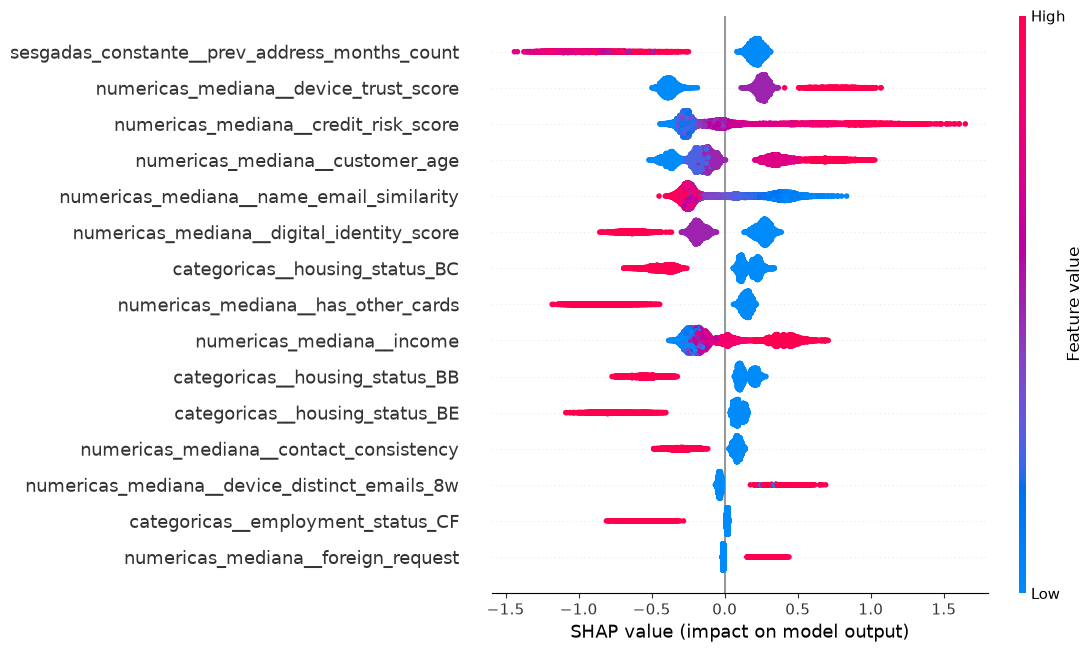

In [175]:
# ============================================================
# 7. Beeswarm Plot - TRAIN
# ============================================================

shap.plots.beeswarm(
    shap_values_train,
    max_display=15
)

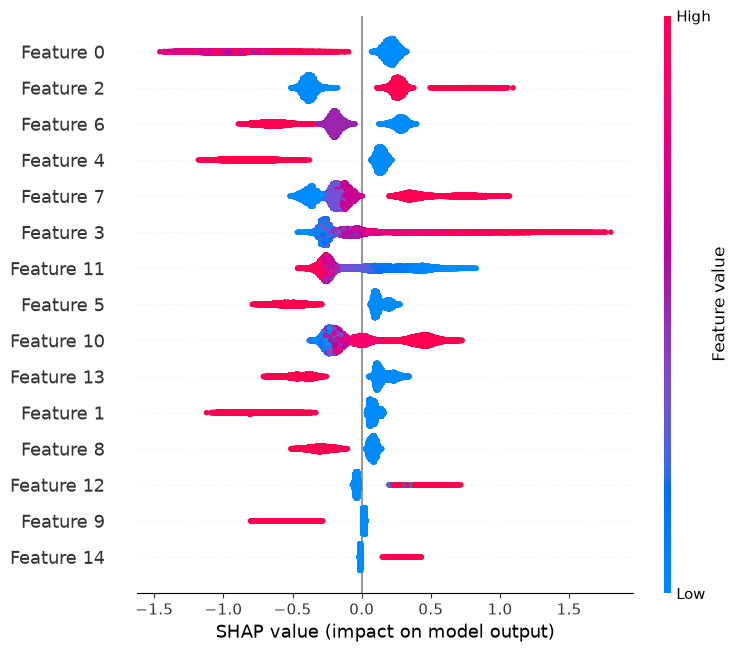

In [176]:
# ============================================================
# 9. Beeswarm Plot - TEST
# ============================================================

shap.plots.beeswarm(
    shap_values_test,
    max_display=15
)

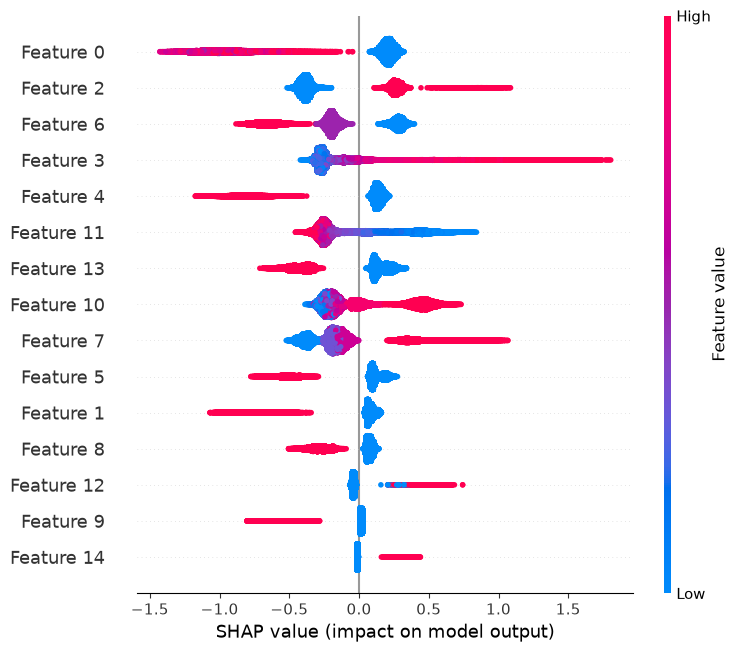

In [178]:
# ============================================================
# 10. Beeswarm Plot - OOT
# ============================================================

shap.plots.beeswarm(
    shap_values_oot,
    max_display=15
)

## LGBM

### Funcion Objetivo

In [180]:
# ============================================================
# 1. Función objetivo para Bayesian Optimization
# ============================================================

def lgbm_evaluate(
    learning_rate,
    num_leaves,
    max_depth,
    n_estimators,
    min_child_samples,
    subsample,
    colsample_bytree,
    reg_alpha,
    reg_lambda
):
    """
    Entrena LightGBM con los datos balanceados y
    evalúa PR-AUC sobre validación real.
    """

    params = {
        "objective": "binary",
        "metric": "average_precision",
        "boosting_type": "gbdt",
        "learning_rate": learning_rate,
        "num_leaves": int(round(num_leaves)),
        "max_depth": int(round(max_depth)),
        "n_estimators": int(round(n_estimators)),
        "min_child_samples": int(round(min_child_samples)),
        "subsample": subsample,
        "colsample_bytree": colsample_bytree,
        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,
        "random_state": 150718,
        "n_jobs": -1,
        "verbosity": -1
    }

    model = LGBMClassifier(**params)

    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    y_val_pred_proba = model.predict_proba(X_val)[:, 1]

    return average_precision_score(
        y_val,
        y_val_pred_proba
    )

### Espacio de búsqueda

In [181]:
# ============================================================
# 2. Espacio de búsqueda
# ============================================================

params_pbounds_lgbm = {
    "learning_rate": (0.01, 0.10),
    "num_leaves": (15, 80),
    "max_depth": (3, 12),
    "n_estimators": (100, 500),
    "min_child_samples": (5, 60),
    "subsample": (0.6, 1.0),
    "colsample_bytree": (0.5, 1.0),
    "reg_alpha": (0.0, 20.0),
    "reg_lambda": (0.0, 20.0)
}

### Optimizacion Bayesiana

In [182]:
# ============================================================
# 3. Optimización Bayesiana
# ============================================================

lgbm_bo = BayesianOptimization(
    f=lgbm_evaluate,
    pbounds=params_pbounds_lgbm,
    random_state=42,
    verbose=2
)

lgbm_bo.maximize(
    init_points=10,
    n_iter=10
)

|   iter    |  target   | colsam... | learni... | max_depth | min_ch... | n_esti... | num_le... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.1692    | 0.6873    | 0.09556   | 9.588     | 37.93     | 162.4     | 25.14     | 1.162     | 17.32     | 0.8404    |
| 2         | 0.1302    | 0.854     | 0.01185   | 11.73     | 50.78     | 184.9     | 26.82     | 3.668     | 6.085     | 0.8099    |
| 3         | 0.1521    | 0.716     | 0.03621   | 8.507     | 12.67     | 216.9     | 38.81     | 9.121     | 15.7      | 0.6799    |
| 4         | 0.1492    | 0.7571    | 0.06332   | 3.418     | 38.41     | 168.2     | 19.23     | 18.98     | 19.31     | 0.9234    |
| 5         | 0.1352    | 0.6523    | 0.01879   | 9.158     | 29.21     | 148.8     | 47.19     | 0.6878    | 18.19     | 0.7035    |
| 6         | 0.1422    | 0.8313    | 0.03805   | 7.681     | 

### Mejores parámetros

In [183]:
# ============================================================
# 4. Mejores parámetros
# ============================================================

best_params_lgbm = lgbm_bo.max["params"].copy()

best_params_lgbm["num_leaves"] = int(round(best_params_lgbm["num_leaves"]))
best_params_lgbm["max_depth"] = int(round(best_params_lgbm["max_depth"]))
best_params_lgbm["n_estimators"] = int(round(best_params_lgbm["n_estimators"]))
best_params_lgbm["min_child_samples"] = int(round(best_params_lgbm["min_child_samples"]))

print("\nMejores parámetros - LightGBM:")
for parametro, valor in best_params_lgbm.items():
    print(f"{parametro}: {valor}")


Mejores parámetros - LightGBM:
colsample_bytree: 0.8887221773011175
learning_rate: 0.06512239530339546
max_depth: 4
min_child_samples: 37
n_estimators: 404
num_leaves: 28
reg_alpha: 4.083679429268066
reg_lambda: 0.7921273486152991
subsample: 0.8253358723045048


### Training

In [184]:
# ============================================================
# 5. Entrenamiento final
# ============================================================

lgbm_best = LGBMClassifier(
    **best_params_lgbm,
    objective="binary",
    metric="average_precision",
    boosting_type="gbdt",
    random_state=150718,
    n_jobs=-1,
    verbosity=-1
)

lgbm_best.fit(
    X_train_resampled,
    y_train_resampled
)

print("Modelo LightGBM entrenado correctamente.")

Modelo LightGBM entrenado correctamente.


### Train Evaluation

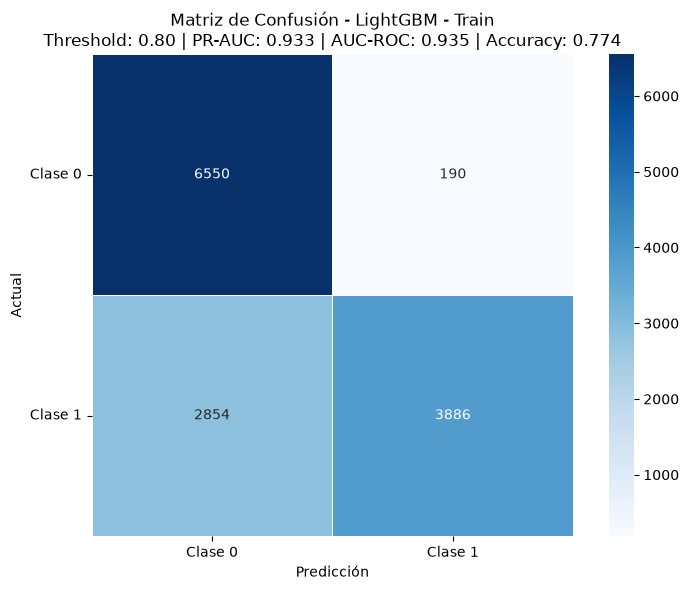


Reporte de Clasificación - LightGBM - Train
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.6965    0.9718    0.8114      6740
     Clase 1     0.9534    0.5766    0.7186      6740

    accuracy                         0.7742     13480
   macro avg     0.8249    0.7742    0.7650     13480
weighted avg     0.8249    0.7742    0.7650     13480

PR-AUC: 0.9334
AUC-ROC: 0.9353
Accuracy: 0.7742


{'model_name': 'LightGBM - Train',
 'threshold': 0.8,
 'pr_auc': 0.9333740895591156,
 'auc_roc': 0.9353482684535392,
 'accuracy': 0.7741839762611276,
 'confusion_matrix': array([[6550,  190],
        [2854, 3886]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 1])}

In [185]:
# ============================================================
# 6. Evaluación - TRAIN
# ============================================================

y_train_pred_proba_lgbm = lgbm_best.predict_proba(X_train_resampled)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_train_resampled,
    y_pred_proba=y_train_pred_proba_lgbm,
    model_name="LightGBM - Train",
    threshold=0.80
)

### Test Evaluation

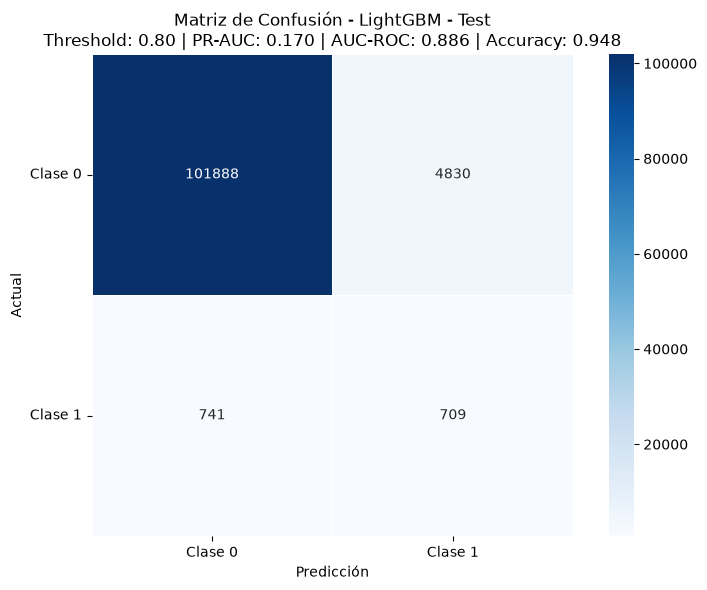


Reporte de Clasificación - LightGBM - Test
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9928    0.9547    0.9734    106718
     Clase 1     0.1280    0.4890    0.2029      1450

    accuracy                         0.9485    108168
   macro avg     0.5604    0.7219    0.5881    108168
weighted avg     0.9812    0.9485    0.9631    108168

PR-AUC: 0.1705
AUC-ROC: 0.8862
Accuracy: 0.9485


{'model_name': 'LightGBM - Test',
 'threshold': 0.8,
 'pr_auc': 0.1704878106143045,
 'auc_roc': 0.8861815057538044,
 'accuracy': 0.9484967827823386,
 'confusion_matrix': array([[101888,   4830],
        [   741,    709]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [186]:
# ============================================================
# 7. Evaluación - TEST
# ============================================================

y_test_pred_proba_lgbm = lgbm_best.predict_proba(X_test)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba_lgbm,
    model_name="LightGBM - Test",
    threshold=0.80
)



### OOT Evaluation

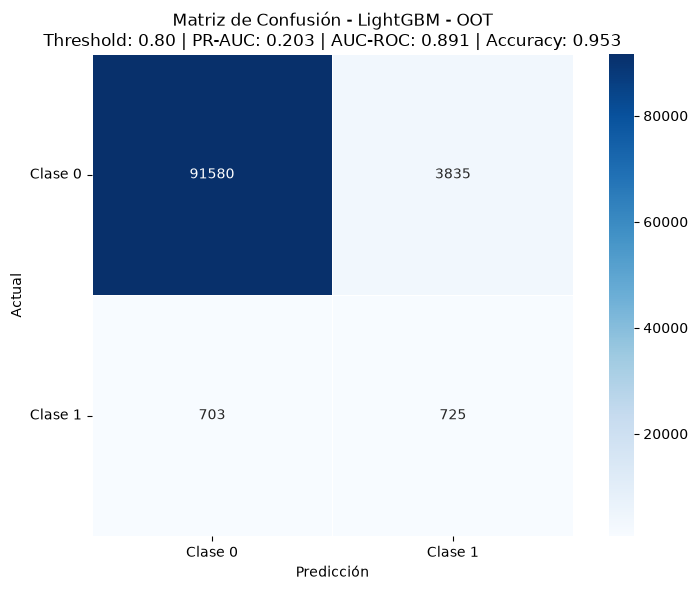


Reporte de Clasificación - LightGBM - OOT
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9924    0.9598    0.9758     95415
     Clase 1     0.1590    0.5077    0.2422      1428

    accuracy                         0.9531     96843
   macro avg     0.5757    0.7338    0.6090     96843
weighted avg     0.9801    0.9531    0.9650     96843

PR-AUC: 0.2029
AUC-ROC: 0.8908
Accuracy: 0.9531


{'model_name': 'LightGBM - OOT',
 'threshold': 0.8,
 'pr_auc': 0.20290816123388258,
 'auc_roc': 0.8907552309819805,
 'accuracy': 0.9531406503309481,
 'confusion_matrix': array([[91580,  3835],
        [  703,   725]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [187]:
# ============================================================
# 8. Evaluación - OOT
# ============================================================

y_oot_pred_proba_lgbm = lgbm_best.predict_proba(X_oot)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba_lgbm,
    model_name="LightGBM - OOT",
    threshold=0.80
)

### Feature Importance

                                                Feature  Importance
0              numericas_mediana__name_email_similarity         364
1                        numericas_mediana__velocity_4w         346
2                  numericas_mediana__credit_risk_score         330
3                  sesgadas_mediana__days_since_request         315
4                sesgadas_mediana__bank_branch_count_8w         286
5                        sesgadas_mediana__zip_count_4w         276
6              numericas_mediana__velocity_ratio_6h_24h         263
7             numericas_mediana__intended_balcon_amount         259
8            numericas_mediana__credit_risk_limit_ratio         256
9           sesgadas_mediana__session_length_in_minutes         245
10             numericas_mediana__velocity_ratio_24h_4w         224
11                  numericas_mediana__email_risk_score         181
12               numericas_constante__bank_months_count         180
13                            numericas_mediana_

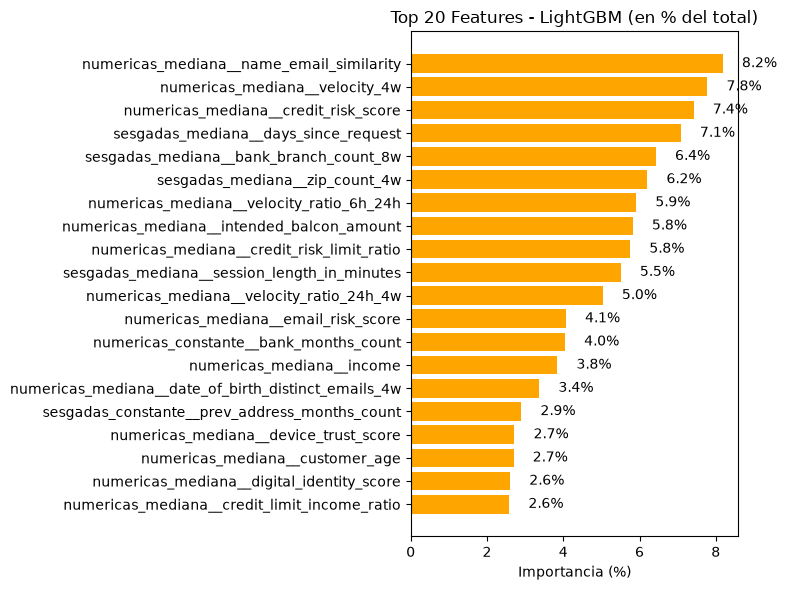

In [188]:
# ============================================================
# 9. Feature Importance
# ============================================================

feature_importance_lgbm = pd.DataFrame({
    "Feature": X_train_resampled.columns,
    "Importance": lgbm_best.feature_importances_
})

feature_importance_lgbm = (
    feature_importance_lgbm
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print(feature_importance_lgbm)

# Top 20
top_n = 20
top_features_lgbm = feature_importance_lgbm.head(top_n).copy()

top_features_lgbm["Importance_pct"] = (
    top_features_lgbm["Importance"] / top_features_lgbm["Importance"].sum() * 100
)

plt.figure(figsize=(8, 6))
bars = plt.barh(
    top_features_lgbm["Feature"][::-1],
    top_features_lgbm["Importance_pct"][::-1],
    color="orange"
)

plt.xlabel("Importancia (%)")
plt.title(f"Top {top_n} Features - LightGBM (en % del total)")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

### Explicabilidad SHAP

In [189]:
# ============================================================
# 10. Explicabilidad SHAP
# ============================================================

explainer_lgbm = shap.TreeExplainer(lgbm_best)

shap_values_train_lgbm = explainer_lgbm(X_train_resampled)
shap_values_test_lgbm = explainer_lgbm(X_test)
shap_values_oot_lgbm = explainer_lgbm(X_oot)

print("SHAP Train:", shap_values_train_lgbm.shape)
print("SHAP Test:", shap_values_test_lgbm.shape)
print("SHAP OOT:", shap_values_oot_lgbm.shape)

SHAP Train: (13480, 48)
SHAP Test: (108168, 48)
SHAP OOT: (96843, 48)


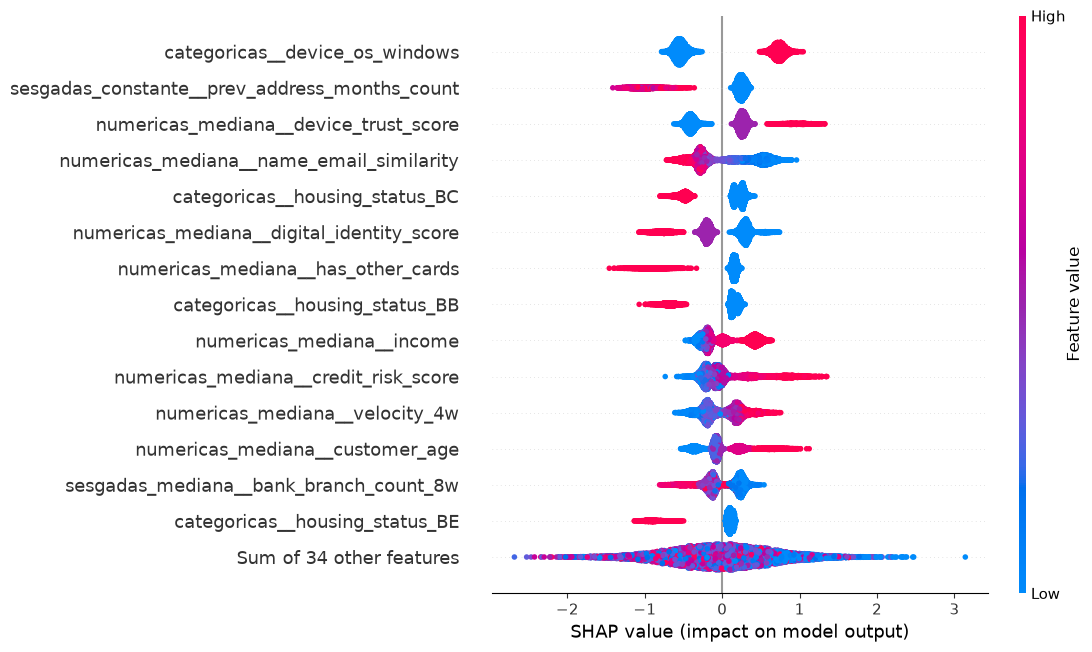

In [190]:
# Beeswarm - TRAIN
shap.plots.beeswarm(
    shap_values_train_lgbm,
    max_display=15
)

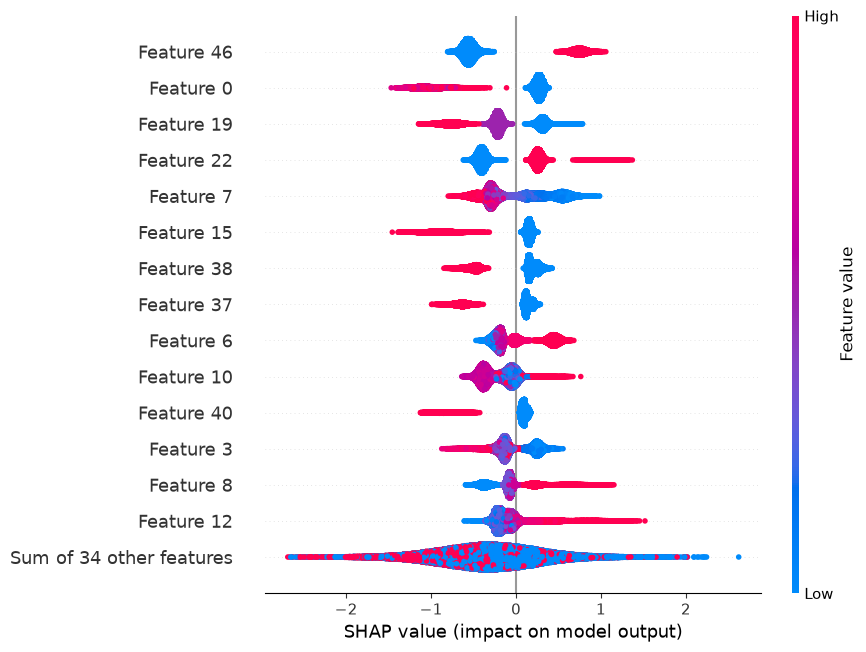

In [191]:
# Beeswarm - TEST
shap.plots.beeswarm(
    shap_values_test_lgbm,
    max_display=15
)

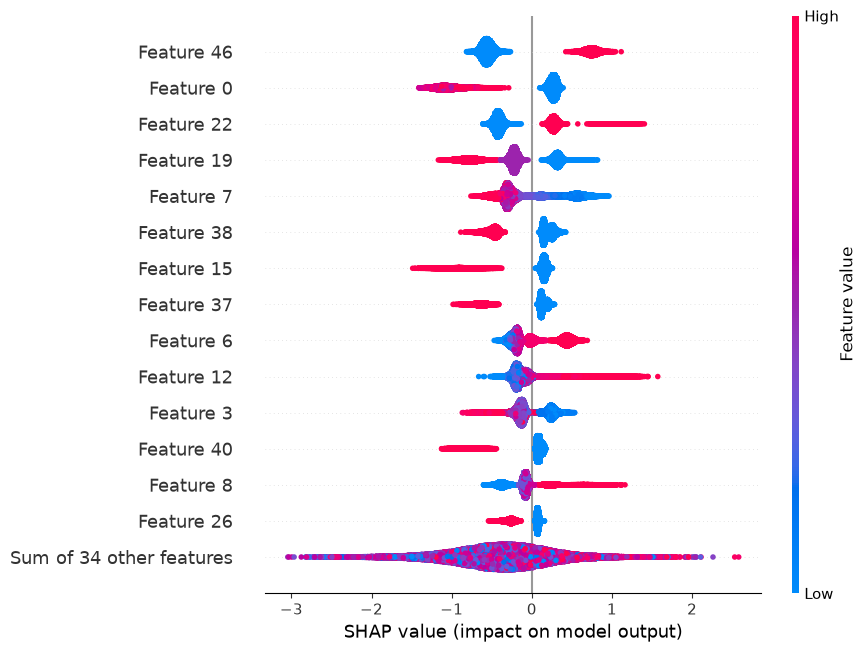

In [192]:
# Beeswarm - OOT
shap.plots.beeswarm(
    shap_values_oot_lgbm,
    max_display=15
)